# Early Hospital Readmission of Diabetic Patients: A Statistical Inference Study

**Midterm project — Data Science**

This notebook is the complete, reproducible analysis behind the report. It follows the order of the report guidelines:

1. Dataset: source, size, feature meanings
2. Data preparation, with the reason for every step
3. Observations before and after preparation
4. Research questions, novelty and exploratory data analysis (EDA)
5. Statistical inference: five hypothesis tests, each with (a) hypotheses and the smallest meaningful effect, (b) the choice of test compared with alternative tests, and (c) the result with a 95% confidence interval and effect size
6. Summary across all tests (with multiple-testing correction), conclusions and limitations

## 1. Dataset

**Source.** UCI Machine Learning Repository, *Diabetes 130-US Hospitals for Years 1999–2008* (dataset ID 296): https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008. The data were extracted from the Cerner Health Facts database and described by Strack et al. (2014), *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records*, BioMed Research International, Article ID 781670.

**What one row is.** One inpatient encounter (hospital admission) of a patient with diabetes at one of 130 US hospitals between 1999 and 2008. An encounter is included only if it was an inpatient admission, diabetes was among the diagnoses, the stay lasted 1–14 days, laboratory tests were performed and medications were administered. One patient can appear in several rows, which matters for independence (Section 2.4).

**Size.** 101,766 rows × 50 columns = **5,088,300 cells**, above the 3,000,000-cell requirement (the arithmetic is computed in the first code cell).

**Feature dictionary**

| Group | Columns | Meaning and type |
|---|---|---|
| Identifiers | `encounter_id`, `patient_nbr` | Unique encounter ID; patient ID (71,518 distinct patients). Labels, not quantities. |
| Demographics | `race` (5 values), `gender` (3), `age` (10 ten-year bands, `[0-10)` … `[90-100)`), `weight` (9 bands) | Nominal; `age` is ordinal. |
| Admission and discharge | `admission_type_id` (8 codes, e.g. 1 Emergency, 2 Urgent, 3 Elective; 5, 6, 8 mean "not available"), `discharge_disposition_id` (26 codes, e.g. 1 home, 3 skilled nursing facility, 11 expired), `admission_source_id` (17 codes, e.g. 7 emergency room) | Nominal codes: the numbers are category labels. |
| Hospital stay | `time_in_hospital` (days, 1–14), `payer_code` (17 payers), `medical_specialty` (72 specialties of the admitting physician) | Count; nominal. |
| Workload during the stay | `num_lab_procedures`, `num_procedures` (non-laboratory procedures), `num_medications` (distinct generic drugs given), `number_diagnoses` (diagnoses entered) | Counts. |
| Use of care in the preceding year | `number_outpatient`, `number_emergency`, `number_inpatient` | Counts of visits in the year before the encounter. |
| Diagnoses | `diag_1` (primary), `diag_2`, `diag_3` (secondary) | ICD-9-CM codes; 716–789 distinct values each. |
| Laboratory results | `max_glu_serum` (None, Norm, >200, >300), `A1Cresult` (None, Norm, >7, >8) | Ordinal; "None" means the test was not performed. |
| 23 diabetes medications | `metformin`, `repaglinide`, …, `insulin`, …, `metformin-pioglitazone` | "No" (not prescribed), "Steady", "Up" or "Down" (dose change during the encounter). |
| Medication summary | `change` (Ch/No: any diabetes-drug dose change), `diabetesMed` (Yes/No: any diabetes drug prescribed) | Binary. |
| **Target** | `readmitted` | "<30" (readmitted within 30 days), ">30" (readmitted after 30 days), "NO" (no recorded readmission). |

In [1]:
# %%
# ==================================================================
# 0. Setup: libraries, global constants, plotting style, helpers
# ==================================================================
import io
import os
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.special import expit

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

ALPHA = 0.05            # significance level used for every test
SEED = 20261019         # one seed for every random procedure (reproducible)
rng = np.random.default_rng(SEED)

# Readmission classes always appear in this order and with these colours
CLASS_ORDER = ["NO", ">30", "<30"]
CLASS_COLORS = {"NO": "#2a78d6", ">30": "#eb6834", "<30": "#1baf7a"}
BEFORE_COLOR, AFTER_COLOR = "#898781", "#6250d6"
INK, INK_2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "font.size": 10,
})


def fmt_p(p, log10_p=None):
    # p-values below the smallest positive double underflow to 0.
    # They are then reported as "< 1e-300" together with log10(p).
    if p is None or np.isnan(p):
        return "n/a"
    if p >= 0.001:
        return f"{p:.4f}"
    if p >= 1e-300:
        return f"{p:.2e}"
    if log10_p is not None and np.isfinite(log10_p):
        return f"< 1e-300 (log10 p = {log10_p:.1f})"
    return "< 1e-300"


def wilson_ci(successes, n, conf=0.95):
    # Wilson score interval for a binomial proportion (works on arrays)
    z = stats.norm.ppf(0.5 + conf / 2)
    successes = np.asarray(successes, dtype=float)
    n = np.asarray(n, dtype=float)
    p = successes / n
    denominator = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denominator
    return centre - half_width, centre + half_width


def cramers_v(table):
    # Cramer's V from the Pearson chi-square statistic (no continuity correction)
    table = np.asarray(table)
    chi2_value = stats.chi2_contingency(table, correction=False)[0]
    return float(np.sqrt(chi2_value / (table.sum() * (min(table.shape) - 1))))


print("Libraries loaded. numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", __import__("scipy").__version__)

Libraries loaded. numpy 2.3.5 | pandas 2.3.3 | scipy 1.16.3


In [2]:
# %%
# ==================================================================
# 1. Load the dataset and check the 3-million-cell requirement
# ==================================================================
DOWNLOAD_URLS = [
    "https://archive.ics.uci.edu/static/public/296/"
    "diabetes+130-us+hospitals+for+years+1999-2008.zip",
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "00296/dataset_diabetes.zip",
]
LOCAL_CANDIDATES = [
    "diabetic_data.csv",
    os.path.join("dataset_diabetes", "diabetic_data.csv"),
]

csv_path = next((path for path in LOCAL_CANDIDATES if os.path.isfile(path)), None)

if csv_path is None:
    for url in DOWNLOAD_URLS:
        try:
            with urllib.request.urlopen(url, timeout=120) as response:
                archive = zipfile.ZipFile(io.BytesIO(response.read()))
            member = next(name for name in archive.namelist()
                          if name.endswith("diabetic_data.csv"))
            with open("diabetic_data.csv", "wb") as file:
                file.write(archive.read(member))
            csv_path = "diabetic_data.csv"
            break
        except Exception as error:
            print(f"Download failed from {url}: {error}")

if csv_path is None:
    raise FileNotFoundError(
        "diabetic_data.csv was not found locally and could not be downloaded."
    )

# Read every value as text. keep_default_na=False stops pandas from turning
# the valid categories "None" (lab test not done) and "NO" into NaN.
df = pd.read_csv(csv_path, dtype=str, keep_default_na=False)

for col in df.columns:
    df[col] = df[col].str.strip()

# Untouched copy of the original data, used for the before/after comparison
raw_df = df.copy()

rows, columns = raw_df.shape
total_cells = rows * columns

print("ORIGINAL DATASET")
print("File:", csv_path)
print("Number of instances (encounters):", f"{rows:,}")
print("Number of attributes:", f"{columns:,}")
print(f"Arithmetic: {rows:,} × {columns:,} = {total_cells:,}")
print("At least 3 million cells:", "YES" if total_cells >= 3_000_000 else "NO")

ORIGINAL DATASET
File: diabetic_data.csv
Number of instances (encounters): 101,766
Number of attributes: 50
Arithmetic: 101,766 × 50 = 5,088,300
At least 3 million cells: YES


## 2. Data preparation

Every step below is applied in this order. The table states what each step does and why.

| Step | What is done | Why |
|---|---|---|
| 2.1 | Remove exact duplicate records, comparing all columns **except** `encounter_id` | `encounter_id` is unique per row, so a duplicate check that includes it can never find anything. |
| 2.2 | Remove records with `gender = "Unknown/Invalid"` | These are invalid entries, not a gender category (3 rows). |
| 2.3 | Remove encounters that ended in death or hospice (`discharge_disposition_id` 11, 13, 14, 19, 20, 21) | These patients cannot be readmitted, so counting them as "NO readmission" biases every readmission comparison (Strack et al., 2014, apply the same exclusion). |
| 2.4 | Keep one encounter per patient (the first one) | The same patient appears up to 40 times. Repeated encounters of one patient are not independent, and every test in Section 5 assumes independent observations. |
| 2.5 | Drop columns with more than 90% missing values | `weight` is missing for almost every patient and cannot be imputed credibly. |
| 2.6 | Drop near-constant columns by **frequency** (dominant value ≥ 99.5%) | A column where fewer than 0.5% of patients differ carries almost no information. We do not use p-values for this decision: with a handful of patients in the minority category a test has almost no power, so "not significant" is not evidence that the column is irrelevant. |
| 2.7 | Drop the identifier columns | They have served their purpose (2.1 and 2.4) and are not features. |
| 2.8 | Recode hidden missing values, then treat all missing values as an explicit `"Unknown"` category | Codes such as admission type 5, 6, 8 mean "not available": they are missing data disguised as categories. Missingness here is informative (Section 2.8), so imputing the most frequent value would fabricate information. |
| 2.9 | Check value ranges and screen each numeric variable for extreme values | Extreme counts are kept because they are plausible and clinically important. They are capped only in the model-ready matrix, never in the data used for tests. |
| 2.10 | Group high-cardinality codes and encode | The 716–789 ICD-9 diagnosis codes are grouped into ICD-9 chapters; rare specialties are pooled. Everything is then encoded numerically. |

### 2.1–2.4 Row-level cleaning: duplicates, invalid records, death/hospice discharges, one encounter per patient

The dataset has no admission dates, so the encounter with the smallest `encounter_id` is treated as the patient's first recorded encounter (the convention used by Strack et al., 2014). `number_inpatient`, `number_emergency` and `number_outpatient` still describe the year *before* that encounter, so the prior-utilization questions remain answerable.

In [3]:
# %%
# ==================================================================
# 2.1-2.4 Row-level cleaning
# ==================================================================
cleaning_log = []


def log_step(step, rows_before, rows_after):
    cleaning_log.append({
        "Step": step,
        "Rows before": rows_before,
        "Rows removed": rows_before - rows_after,
        "Rows after": rows_after,
    })


ID_COLUMNS = ["encounter_id", "patient_nbr"]

# ------------------------------------------------------------------
# 2.1 Exact duplicate records (encounter_id ignored)
# ------------------------------------------------------------------
n_before = len(df)
duplicate_mask = df.drop(columns=["encounter_id"]).duplicated(keep="first")
identical_across_patients = int(df.drop(columns=ID_COLUMNS).duplicated().sum())
df = df.loc[~duplicate_mask].copy()
log_step("2.1 Exact duplicate records", n_before, len(df))

print("2.1 Exact duplicate records (all columns except encounter_id):",
      int(duplicate_mask.sum()))
print("    Identical clinical records even across different patients:",
      identical_across_patients)

# Patient-level duplication: how many encounters does each patient have?
encounters_per_patient = df.groupby("patient_nbr").size()
repeat_share = (encounters_per_patient[encounters_per_patient > 1].sum()
                / len(df) * 100)
print(f"\n    Distinct patients: {encounters_per_patient.size:,} "
      f"across {len(df):,} encounters")
print(f"    Encounters per patient: max {encounters_per_patient.max()}, "
      f"mean {encounters_per_patient.mean():.2f}")
print(f"    Encounters that belong to patients with 2+ encounters: {repeat_share:.1f}%")
print(pd.cut(encounters_per_patient, bins=[0, 1, 2, 5, np.inf],
             labels=["1", "2", "3-5", "6+"]).value_counts().sort_index()
      .rename("Patients").to_string())

# ------------------------------------------------------------------
# 2.2 Invalid gender entries
# ------------------------------------------------------------------
gender_invalid_mask = df["gender"] == "Unknown/Invalid"
print("2.2 Gender 'Unknown/Invalid' rows kept and set to missing:",
      int(gender_invalid_mask.sum()))
df.loc[gender_invalid_mask, "gender"] = np.nan

# ------------------------------------------------------------------
# 2.3 Encounters ending in death or hospice (patient cannot be readmitted)
# ------------------------------------------------------------------
END_OF_LIFE_CODES = {
    "11": "Expired",
    "13": "Hospice / home",
    "14": "Hospice / medical facility",
    "19": "Expired at home (hospice)",
    "20": "Expired in a medical facility (hospice)",
    "21": "Expired, place unknown (hospice)",
}
end_of_life_mask = df["discharge_disposition_id"].isin(list(END_OF_LIFE_CODES))
print("\n2.3 Death/hospice discharges removed, by code:")
print(df.loc[end_of_life_mask, "discharge_disposition_id"]
      .map(END_OF_LIFE_CODES).value_counts().to_string())
print("    Their readmission labels (all of these would have counted as outcomes):")
print(df.loc[end_of_life_mask, "readmitted"].value_counts().to_string())

n_before = len(df)
df = df.loc[~end_of_life_mask].copy()
log_step("2.3 Death or hospice discharge", n_before, len(df))

# ------------------------------------------------------------------
# 2.4 One encounter per patient: the first (smallest encounter_id)
# ------------------------------------------------------------------
n_before = len(df)
first_order = pd.to_numeric(df["encounter_id"], errors="raise").sort_values().index
df = (df.loc[first_order]
        .drop_duplicates(subset="patient_nbr", keep="first")
        .sort_index()
        .copy())
assert df["patient_nbr"].is_unique, "More than one encounter per patient remains."
log_step("2.4 Later encounters of the same patient", n_before, len(df))

print("\nROW-LEVEL CLEANING SUMMARY")
print(pd.DataFrame(cleaning_log).to_string(index=False))
print(f"\nRows now: {len(df):,} (one encounter per patient)")

2.1 Exact duplicate records (all columns except encounter_id): 0
    Identical clinical records even across different patients: 0

    Distinct patients: 71,518 across 101,766 encounters
    Encounters per patient: max 40, mean 1.42
    Encounters that belong to patients with 2+ encounters: 46.2%
1      54745
2      10434
3-5     5466
6+       873
2.2 Gender 'Unknown/Invalid' rows kept and set to missing: 3

2.3 Death/hospice discharges removed, by code:
discharge_disposition_id
Expired                                    1642
Hospice / home                              399
Hospice / medical facility                  372
Expired at home (hospice)                     8
Expired in a medical facility (hospice)       2
    Their readmission labels (all of these would have counted as outcomes):
readmitted
NO     2337
<30      43
>30      43

ROW-LEVEL CLEANING SUMMARY
                                    Step  Rows before  Rows removed  Rows after
             2.1 Exact duplicate records     

### 2.5 Columns with more than 90% missing values

In [4]:
# %%
# ==================================================================
# 2.5 Identify and drop columns with more than 90% missing values
# ==================================================================
missing_mask = df.eq("?") | df.eq("")
missing_percentage = missing_mask.mean() * 100

print("Columns that contain missing values ('?' or blank):")
print(missing_percentage[missing_percentage > 0]
      .sort_values(ascending=False).round(2).rename("Missing %").to_string())

columns_dropped_missing = missing_percentage[missing_percentage > 90].index.tolist()
print("\nColumns removed (>90% missing):", columns_dropped_missing)

df = df.drop(columns=columns_dropped_missing)
missing_mask = df.eq("?") | df.eq("")

print("Shape after removing high-missingness columns:", df.shape)
print("Is weight still present?", "weight" in df.columns)

Columns that contain missing values ('?' or blank):
weight               96.02
medical_specialty    48.08
payer_code           43.46
race                  2.74
diag_3                1.75
diag_2                0.42
diag_1                0.01

Columns removed (>90% missing): ['weight']
Shape after removing high-missingness columns: (69990, 49)
Is weight still present? False


### 2.6 Near-constant columns (decided by frequency, not by p-values)

A column is near-constant when one value covers at least 99.5% of patients. The threshold was fixed before looking at the outcome. Identifiers, the target and the two laboratory-result columns are protected because they are needed for the analysis.

In [5]:
# %%
# ==================================================================
# 2.6 Near-constant columns (frequency rule)
# ==================================================================
DOMINANT_THRESHOLD = 0.995

protected_columns = {"encounter_id", "patient_nbr", "readmitted",
                     "max_glu_serum", "A1Cresult"}

MEDICATION_COLUMNS = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide",
    "glimepiride", "acetohexamide", "glipizide", "glyburide",
    "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose",
    "miglitol", "troglitazone", "tolazamide", "examide", "citoglipton",
    "insulin", "glyburide-metformin", "glipizide-metformin",
    "glimepiride-pioglitazone", "metformin-rosiglitazone",
    "metformin-pioglitazone",
]

near_constant_details = []

for col in df.columns:
    if col in protected_columns:
        continue
    observed = df.loc[~missing_mask[col], col]
    if observed.empty:
        continue
    shares = observed.value_counts(normalize=True)
    if shares.iloc[0] >= DOMINANT_THRESHOLD:
        near_constant_details.append({
            "Column": col,
            "Dominant value": shares.index[0],
            "Dominant %": round(shares.iloc[0] * 100, 3),
            "Patients not in dominant value": int((observed != shares.index[0]).sum()),
            "Distinct values": observed.nunique(),
        })

near_constant_details = (pd.DataFrame(near_constant_details)
                         .sort_values("Patients not in dominant value"))
near_constant = near_constant_details["Column"].tolist()
exact_constant = near_constant_details.loc[
    near_constant_details["Distinct values"] == 1, "Column"].tolist()

print(f"Near-constant columns (dominant value >= {DOMINANT_THRESHOLD:.1%}):")
print(near_constant_details.to_string(index=False))
print("\nExactly constant columns:", exact_constant)
print(f"Largest minority among them: "
      f"{near_constant_details['Patients not in dominant value'].max()} patients "
      f"out of {len(df):,} "
      f"({near_constant_details['Patients not in dominant value'].max() / len(df):.2%})")
print("Non-medication columns among them:",
      [c for c in near_constant if c not in MEDICATION_COLUMNS])



Near-constant columns (dominant value >= 99.5%):
                  Column Dominant value  Dominant %  Patients not in dominant value  Distinct values
                 examide             No     100.000                               0                1
             citoglipton             No     100.000                               0                1
glimepiride-pioglitazone             No     100.000                               0                1
           acetohexamide             No      99.999                               1                2
  metformin-pioglitazone             No      99.999                               1                2
 metformin-rosiglitazone             No      99.997                               2                2
            troglitazone             No      99.996                               3                2
     glipizide-metformin             No      99.990                               7                2
             tolbutamide             No   

In [6]:
# %%
# ==================================================================
# Benjamini-Hochberg false discovery rate adjustment
# ==================================================================
def benjamini_hochberg(p_values):
    p = np.asarray(p_values, dtype=float)
    m = len(p)

    if m == 0:
        return np.array([])

    order = np.argsort(p)
    ranked_p = p[order]

    adjusted = ranked_p * m / np.arange(1, m + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.minimum(adjusted, 1.0)

    result = np.empty(m)
    result[order] = adjusted

    return result


# Quick self-check against a hand-computed example
assert np.allclose(benjamini_hochberg([0.01, 0.04, 0.03, 0.20]),
                   [0.04, 0.0533333, 0.0533333, 0.20])
print("benjamini_hochberg() defined and verified.")

benjamini_hochberg() defined and verified.


In [7]:
# %%
# ==================================================================
# 2.6b Near-constant (but not exactly constant) columns:
#      chi-square test of independence against the 3-class outcome
#      (readmitted: NO / >30 / <30) before deciding to drop
# ==================================================================
ALPHA = 0.05
N_SIM = 20_000
rng = np.random.default_rng(42)

outcome = pd.Categorical(df["readmitted"], categories=CLASS_ORDER)
y = outcome.codes                                   # 0, 1, 2
class_totals = np.bincount(y, minlength=len(CLASS_ORDER))

near_not_exact = [c for c in near_constant if c not in exact_constant]
dominant_value = near_constant_details.set_index("Column")["Dominant value"]


def pearson_stat(obs, exp):
    return ((obs - exp) ** 2 / exp).sum(axis=-1)


test_rows = []
for col in near_not_exact:
    off = df[col].ne(dominant_value[col]).to_numpy()      # not the dominant value
    n_off = int(off.sum())
    obs_off = np.bincount(y[off], minlength=len(CLASS_ORDER))
    obs_dom = class_totals - obs_off
    t = np.vstack([obs_dom, obs_off])                      # 2 x 3 table
    expected = np.outer(t.sum(axis=1), t.sum(axis=0)) / t.sum()

    if expected.min() >= 5:
        stat, p_value, dof, _ = stats.chi2_contingency(t, correction=False)
        method = "Pearson chi-square (df = 2)"
    else:
        # Too few patients for the chi-square approximation: Monte Carlo p-value
        exp_off = n_off * class_totals / class_totals.sum()
        exp_dom = (len(y) - n_off) * class_totals / class_totals.sum()
        stat = pearson_stat(obs_off, exp_off) + pearson_stat(obs_dom, exp_dom)
        sim_off = rng.multivariate_hypergeometric(class_totals, n_off, size=N_SIM)
        sim_dom = class_totals - sim_off
        sim_stat = pearson_stat(sim_off, exp_off) + pearson_stat(sim_dom, exp_dom)
        p_value = (1 + np.sum(sim_stat >= stat - 1e-9)) / (N_SIM + 1)
        method = f"Monte Carlo chi-square ({N_SIM:,} sims)"

    row = {"Column": col, "Patients off dominant value": n_off}
    for k, cls in enumerate(CLASS_ORDER):
        row[f"% {cls} (off dominant)"] = round(t[1, k] / t[1].sum() * 100, 2)
    row["Min expected count"] = round(expected.min(), 2)
    row["Method"] = method
    row["chi2"] = round(float(stat), 3)
    row["p-value"] = p_value
    test_rows.append(row)

near_constant_tests = pd.DataFrame(test_rows)
near_constant_tests["BH-adjusted p"] = benjamini_hochberg(near_constant_tests["p-value"])
near_constant_tests["Decision"] = np.where(
    near_constant_tests["BH-adjusted p"] < ALPHA, "Keep", "Drop")

print("Independence of near-constant columns from the 3-class outcome:")
print(near_constant_tests.sort_values("p-value").to_string(index=False))

near_constant_keep = near_constant_tests.loc[
    near_constant_tests["Decision"] == "Keep", "Column"].tolist()
columns_dropped_near_constant = exact_constant + [
    c for c in near_not_exact if c not in near_constant_keep]

print("\nExactly constant (dropped):", exact_constant)
print("Near-constant, kept after test:", near_constant_keep)
print("Near-constant, dropped after test:",
      [c for c in near_not_exact if c not in near_constant_keep])

Independence of near-constant columns from the 3-class outcome:
                 Column  Patients off dominant value  % NO (off dominant)  % >30 (off dominant)  % <30 (off dominant)  Min expected count                               Method   chi2  p-value  BH-adjusted p Decision
               acarbose                          200                49.00                 43.50                  7.50               17.96          Pearson chi-square (df = 2) 12.766 0.001690       0.016900     Keep
               miglitol                           20                35.00                 60.00                  5.00                1.80 Monte Carlo chi-square (20,000 sims)  7.366 0.027349       0.136743     Drop
         chlorpropamide                           71                56.34                 39.44                  4.23                6.38          Pearson chi-square (df = 2)  3.212 0.200679       0.668930     Drop
    glipizide-metformin                            7                42.86   

**Benjamini–Hochberg procedure.** Defined here and used twice later: to adjust the cell-wise residual p-values in Test 5 and to adjust the p-values of all five tests together in Section 6.

### 2.7 Remove the excluded columns

All near-constant columns are dropped, including `acarbose`. Fewer than 0.5% of patients received or changed any of these drugs, so estimates for their categories would be too imprecise to interpret, and their one-hot columns would be almost entirely zeros. The identifiers are dropped last, after they were used for de-duplication.

In [8]:
# %%
# ==================================================================
# 2.7 Remove near-constant and identifier columns
# ==================================================================
excluded_columns = (
    set(columns_dropped_missing)
    | set(columns_dropped_near_constant)
    | set(ID_COLUMNS)
)

columns_to_remove = [col for col in df.columns if col in excluded_columns]
df = df.drop(columns=columns_to_remove)

print("Columns removed in this step:")
print(columns_to_remove)
print("\nShape after all column exclusions:", df.shape)
print("Is weight still present?", "weight" in df.columns)
print("\nRetained columns:")
print(df.columns.tolist())

Columns removed in this step:
['encounter_id', 'patient_nbr', 'chlorpropamide', 'acetohexamide', 'tolbutamide', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']

Shape after all column exclusions: (69990, 35)
Is weight still present? False

Retained columns:
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'insulin', 'glyburide-metformin', 'change', 'diabetesMed', 'readmitted']


### 2.8 Hidden missing values and missing-value treatment

Three ID columns contain codes that mean "no information": admission type 5 (Not Available), 6 (NULL), 8 (Not Mapped); discharge disposition 18 (NULL), 25 (Not Mapped), 26 (Unknown/Invalid); admission source 9 and 15 (Not Available), 17 (NULL), 20 (Not Mapped), 21 (Unknown/Invalid). They are converted to missing values first, so that they are counted honestly. Admission-type codes are also replaced by their labels.

In [9]:
# %%
# ==================================================================
# 2.8a Validate the target, recode hidden missing values, report missingness
# ==================================================================
n_before = len(df)
df = df.loc[df["readmitted"].isin(CLASS_ORDER)].copy()
print("Rows removed for an invalid target value:", n_before - len(df))

# '?' and blank strings become real missing values
df = df.mask(df.isin(["?", ""]))

HIDDEN_MISSING_CODES = {
    "admission_type_id": {"5": "Not Available", "6": "NULL", "8": "Not Mapped"},
    "discharge_disposition_id": {"18": "NULL", "25": "Not Mapped",
                                 "26": "Unknown/Invalid"},
    "admission_source_id": {"9": "Not Available", "15": "Not Available",
                            "17": "NULL", "20": "Not Mapped",
                            "21": "Unknown/Invalid"},
}

hidden_report = []
for col, codes in HIDDEN_MISSING_CODES.items():
    hidden = df[col].isin(list(codes))
    hidden_report.append({"Column": col,
                          "Codes treated as missing": ", ".join(codes),
                          "Rows recoded": int(hidden.sum()),
                          "% of rows": round(hidden.mean() * 100, 2)})
    df.loc[hidden, col] = np.nan

print("\nHidden missing codes converted to missing values:")
print(pd.DataFrame(hidden_report).to_string(index=False))

# Replace admission-type codes by readable labels
ADMISSION_TYPE_LABELS = {"1": "Emergency", "2": "Urgent", "3": "Elective",
                         "4": "Newborn", "7": "Trauma Center"}
unexpected_codes = set(df["admission_type_id"].dropna()) - set(ADMISSION_TYPE_LABELS)
assert not unexpected_codes, f"Unmapped admission types: {unexpected_codes}"
position = df.columns.get_loc("admission_type_id")
df.insert(position, "admission_type", df["admission_type_id"].map(ADMISSION_TYPE_LABELS))
df = df.drop(columns="admission_type_id")

# Numeric columns: convert, and fail loudly if any value is not a number
NUMERIC_COLUMNS = [
    "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses",
]
for col in NUMERIC_COLUMNS:
    df[col] = pd.to_numeric(df[col], errors="raise").astype("int64")

missing_counts = df.isna().sum()
missing_counts = missing_counts[missing_counts > 0]
print("\nMissing values before treatment:")
print(pd.DataFrame({
    "Missing values": missing_counts,
    "Missing %": (missing_counts / len(df) * 100).round(2),
}).sort_values("Missing values", ascending=False).to_string())

# Missingness of secondary diagnoses is structural: it occurs when few
# diagnoses were recorded, so it is information, not noise.
print("\nMean number_diagnoses when a secondary diagnosis is missing vs recorded:")
for col in ["diag_2", "diag_3"]:
    is_missing = df[col].isna()
    print(f"  {col}: missing {df.loc[is_missing, 'number_diagnoses'].mean():.2f} "
          f"vs recorded {df.loc[~is_missing, 'number_diagnoses'].mean():.2f} "
          f"(n missing = {int(is_missing.sum())})")

# Is missingness of medical_specialty and payer_code related to the outcome?
print("\nEarly-readmission rate (<30) when the value is missing vs recorded:")
for col in ["medical_specialty", "payer_code", "race", "admission_type"]:
    is_missing = df[col].isna()
    rate_missing = df.loc[is_missing, "readmitted"].eq("<30").mean()
    rate_recorded = df.loc[~is_missing, "readmitted"].eq("<30").mean()
    print(f"  {col:<18} missing {rate_missing:.2%} vs recorded {rate_recorded:.2%}")

Rows removed for an invalid target value: 0

Hidden missing codes converted to missing values:
                  Column Codes treated as missing  Rows recoded  % of rows
       admission_type_id                  5, 6, 8          7893      11.28
discharge_disposition_id               18, 25, 26          3252       4.65
     admission_source_id        9, 15, 17, 20, 21          5069       7.24

Missing values before treatment:
                          Missing values  Missing %
medical_specialty                  33654      48.08
payer_code                         30416      43.46
admission_type                      7893      11.28
admission_source_id                 5069       7.24
discharge_disposition_id            3252       4.65
race                                1919       2.74
diag_3                              1224       1.75
diag_2                               293       0.42
diag_1                                10       0.01
gender                                 3       0.00

**Why an explicit "Unknown" category instead of the most frequent value.** The output above shows that missingness is not random. A missing secondary diagnosis goes with fewer recorded diagnoses, and the early-readmission rate differs between missing and recorded values. Filling in the mode (e.g. "Caucasian" for race or the commonest ICD-9 code) would invent values and hide this pattern. An explicit "Unknown" category keeps every patient and lets missingness carry its own information. No numeric column has missing values.

In [10]:
# %%
# ==================================================================
# 2.8b Missing-value treatment (rule depends on variable type and % missing)
#   Categorical, < 5% missing  -> mode imputation
#   Categorical, >= 5% missing -> separate "Unknown" category
#   Binary                     -> mode imputation
#   Numeric                    -> median imputation
# ==================================================================
MISSING_THRESHOLD = 5.0                                   # percent
BINARY_COLUMNS = [c for c in ["change", "diabetesMed"] if c in df.columns]
categorical_columns = [c for c in df.columns
                       if c not in NUMERIC_COLUMNS + BINARY_COLUMNS + ["readmitted"]]

imputation_report = []


def log_imputation(col, missing_count, treatment):
    imputation_report.append({
        "Column": col,
        "Type": ("binary" if col in BINARY_COLUMNS else
                 "numeric" if col in NUMERIC_COLUMNS else "categorical"),
        "Missing values": missing_count,
        "Missing %": round(missing_count / len(df) * 100, 2),
        "Treatment": treatment,
    })


# 1) Categorical variables
for col in categorical_columns:
    missing_count = int(df[col].isna().sum())
    if missing_count == 0:
        continue
    if missing_count / len(df) * 100 < MISSING_THRESHOLD:
        mode_value = df[col].mode()[0]
        df[col] = df[col].fillna(mode_value)
        log_imputation(col, missing_count, f"Mode imputation ('{mode_value}')")
    else:
        df[col] = df[col].fillna("Unknown")
        log_imputation(col, missing_count, "Explicit 'Unknown' category")

# 2) Binary variables: mode
for col in BINARY_COLUMNS:
    missing_count = int(df[col].isna().sum())
    if missing_count == 0:
        continue
    mode_value = df[col].mode()[0]
    df[col] = df[col].fillna(mode_value)
    log_imputation(col, missing_count, f"Mode imputation ('{mode_value}')")

# 3) Numeric variables: median
for col in NUMERIC_COLUMNS:
    missing_count = int(df[col].isna().sum())
    if missing_count == 0:
        continue
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)
    log_imputation(col, missing_count, f"Median imputation ({median_value:g})")

print("Missing-value treatment:")
print(pd.DataFrame(imputation_report).to_string(index=False))

total_missing = int(df.isna().sum().sum())
print("\nMissing values after treatment:", total_missing)
assert total_missing == 0, "Some missing values remain."
print("Rows:", f"{len(df):,}", "| Columns:", df.shape[1])

Missing-value treatment:
                  Column        Type  Missing values  Missing %                     Treatment
                    race categorical            1919       2.74 Mode imputation ('Caucasian')
                  gender categorical               3       0.00    Mode imputation ('Female')
          admission_type categorical            7893      11.28   Explicit 'Unknown' category
discharge_disposition_id categorical            3252       4.65         Mode imputation ('1')
     admission_source_id categorical            5069       7.24   Explicit 'Unknown' category
              payer_code categorical           30416      43.46   Explicit 'Unknown' category
       medical_specialty categorical           33654      48.08   Explicit 'Unknown' category
                  diag_1 categorical              10       0.01       Mode imputation ('414')
                  diag_2 categorical             293       0.42       Mode imputation ('250')
                  diag_3 categorica

### 2.9 Outlier detection and treatment

The earlier version flagged outliers with a Local Outlier Factor on a two-component PCA that explained only 18.75% of the variance. That flagged points at the edge of an arbitrary projection, which have no clinical meaning, so it is replaced by checks on each variable:

1. **Validity check.** Values outside the possible range (e.g. a stay outside 1–14 days, which the dataset's inclusion criteria forbid, or negative counts) are errors and would be removed.
2. **Extreme-value screen.** For every numeric variable we report Tukey's far-out fence (Q3 + 3·IQR) and the 99.5th percentile. For the zero-inflated visit counts the IQR is 0, so Tukey's rule would label every non-zero value an outlier; the 99.5th percentile is the usable rule there.
3. **Decision.** Extreme values (e.g. 81 medications, 42 outpatient visits) are plausible. They describe the heaviest users of care, exactly the patients most relevant to readmission, so **no rows are deleted**. To limit their leverage in a future model, the encoded matrix (Section 2.10) caps each count at its 99.5th percentile (winsorisation). The data used for the tests stays uncapped: the tests use prior-visit *categories* (0 / 1 / 2+), stay length (bounded at 14 days) and robust methods.

Validity check:
            Column Allowed range Observed range  Invalid values
  time_in_hospital       [1, 14]        [1, 14]               0
num_lab_procedures      [1, inf]       [1, 132]               0
    num_procedures      [0, inf]         [0, 6]               0
   num_medications      [1, inf]        [1, 81]               0
 number_outpatient      [0, inf]        [0, 42]               0
  number_emergency      [0, inf]        [0, 42]               0
  number_inpatient      [0, inf]        [0, 12]               0
  number_diagnoses      [1, inf]        [1, 16]               0
Rows removed as invalid: 0

Performing PCA + Density-Based outlier removal...
PCA Variance Explained by 2 components: 41.12%
Points removed as PCA outliers: 700

Analysis dataset df_clean: 69,290 rows × 35 columns


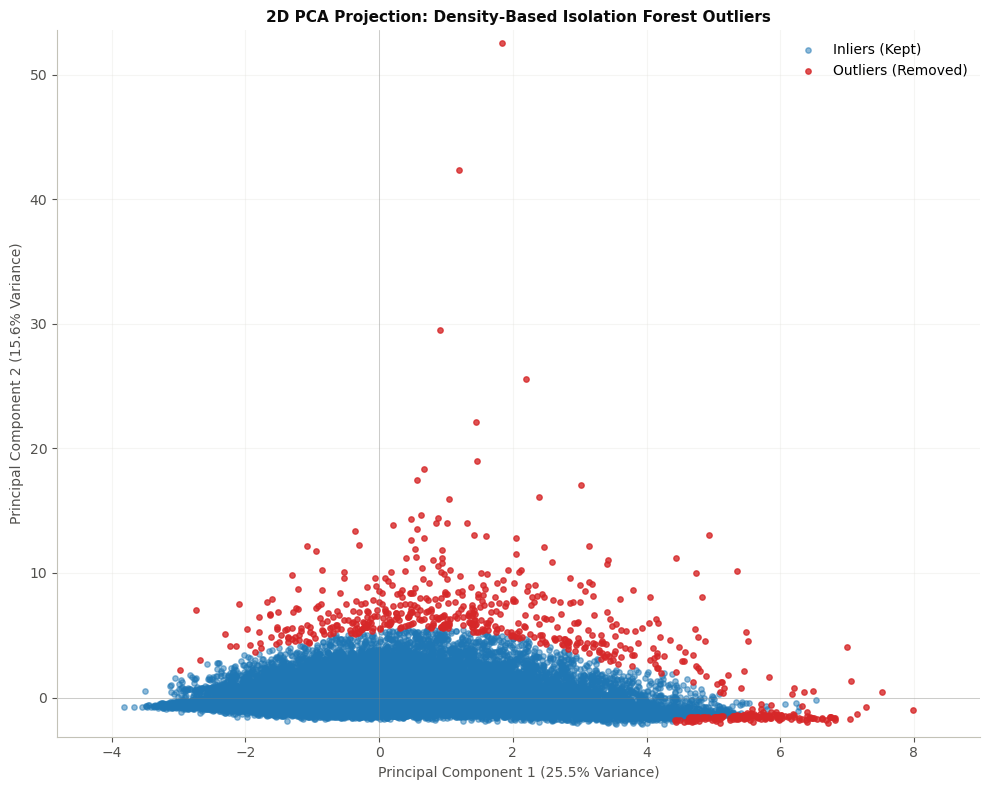

In [11]:
# %%
# ==================================================================
# 2.9 Outlier detection: validity checks, PCA + Isolation Forest
# ==================================================================
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

VALID_RANGES = {                      
    "time_in_hospital": (1, 14),      
    "num_lab_procedures": (1, None),  
    "num_procedures": (0, None),
    "num_medications": (1, None),     
    "number_outpatient": (0, None),
    "number_emergency": (0, None),
    "number_inpatient": (0, None),
    "number_diagnoses": (1, None),
}

invalid_rows = pd.Series(False, index=df.index)
validity_report = []
for col, (low, high) in VALID_RANGES.items():
    bad = df[col] < low
    if high is not None:
        bad |= df[col] > high
    invalid_rows |= bad
    validity_report.append({"Column": col,
                            "Allowed range": f"[{low}, {high if high else 'inf'}]",
                            "Observed range": f"[{df[col].min()}, {df[col].max()}]",
                            "Invalid values": int(bad.sum())})

print("Validity check:")
print(pd.DataFrame(validity_report).to_string(index=False))

n_before = len(df)
df = df.loc[~invalid_rows].copy()

try:
    log_step("2.9 Values outside the valid range", n_before, len(df))
except NameError:
    pass
print("Rows removed as invalid:", n_before - len(df))

# --- PCA + Density-Based Outlier Removal (Isolation Forest) ---
print("\nPerforming PCA + Density-Based outlier removal...")

# 1. Scale the numeric data 
scaler = StandardScaler()
scaled_numeric = scaler.fit_transform(df[NUMERIC_COLUMNS])

# 2. Apply PCA to reduce dimensions to 2D
pca = PCA(n_components=2, random_state=42)
pca_components = pca.fit_transform(scaled_numeric)

# 3. Use Isolation Forest to detect density-based outliers in 2D PCA space
# contamination=0.01 removes the extreme 1% isolated points
iso_forest = IsolationForest(contamination=0.01, random_state=42)
preds = iso_forest.fit_predict(pca_components)

# -1 indicates an outlier, 1 indicates an inlier
outlier_mask = (preds == -1)

# 4. Filter out the outliers
n_before_pca = len(df)
df_clean = df.iloc[~outlier_mask].copy()

print(f"PCA Variance Explained by 2 components: {pca.explained_variance_ratio_.sum()*100:.2f}%")
print(f"Points removed as PCA outliers: {outlier_mask.sum()}")

try:
    log_step("2.9 PCA-based outlier removal", n_before_pca, len(df_clean))
except NameError:
    pass 

print(f"\nAnalysis dataset df_clean: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns")

# --- Visualizing Non-Linear Density Decision Boundary ---
# Create a grid for contour plotting
x_min, x_max = pca_components[:, 0].min() - 1, pca_components[:, 0].max() + 1
y_min, y_max = pca_components[:, 1].min() - 1, pca_components[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

# Decision function values (positive for inliers, negative for outliers)
Z = iso_forest.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 8))

# Plot actual points
plt.scatter(pca_components[~outlier_mask, 0], pca_components[~outlier_mask, 1], 
            c='#1f77b4', alpha=0.5, s=15, label='Inliers (Kept)')

plt.scatter(pca_components[outlier_mask, 0], pca_components[outlier_mask, 1], 
            c='#d62728', alpha=0.8, s=15, label='Outliers (Removed)')

# Plot the precise density boundary (where score = threshold)
plt.contour(xx, yy, Z, levels=[iso_forest.offset_], colors='black', 
            linestyles='--', linewidths=2)

plt.title('2D PCA Projection: Density-Based Isolation Forest Outliers')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)')
plt.axhline(0, color='grey', linewidth=0.5, alpha=0.5)
plt.axvline(0, color='grey', linewidth=0.5, alpha=0.5)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 2.10 Grouping high-cardinality codes and encoding

* **Diagnoses.** Each ICD-9-CM code is mapped to its ICD-9 chapter (e.g. 390–459 Circulatory, 460–519 Respiratory). Codes 250.xx are kept as a separate "Diabetes" group because every patient here is diabetic and diabetes as the *primary* reason for admission is clinically distinct. V and E codes form their own groups. This reduces about 700–760 distinct codes per column (in the cleaned data) to 20 groups.
* **Medical specialty.** Specialties with at least 1% of patients are kept and the rest pooled into "Other"; "Unknown" stays separate.
* **Encoding.** Counts stay numeric (capped at P99.5), age becomes an ordinal code 0–9, `change` and `diabetesMed` become 0/1, all nominal columns are one-hot encoded, and the target is one-hot encoded (`readmitted_lt30` is the early-readmission indicator).

In [12]:
# %%
# ==================================================================
# 2.10 Attribute Encoding According to Specified Mechanisms
# ==================================================================
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

df_model = df_clean.copy()

print("="*60)
print("ENCODING PROCESS REPORT")
print("="*60)

# ------------------------------------------------------------------
# 1. Age: Ordinal floor division on lower bound ([0,10) -> 0, ..., [90,100) -> 9)
# ------------------------------------------------------------------
df_model['age'] = df_model['age'].astype(str)
age_lower_bound = df_model['age'].str.extract(r'\[(\d+)').astype(int)
age_encoded = (age_lower_bound // 10).rename(columns={0: 'age'}).astype('int8')
print(f"[1] Age: Ordinal encoding applied. Mapped intervals (e.g., '[50-60)') to integers (0-9) via floor division.")

# ------------------------------------------------------------------
# 8. Drop examide and citogliptin prior to medication encoding
# ------------------------------------------------------------------
cols_to_remove = ['examide', 'citogliptin']
removed_cols = [c for c in cols_to_remove if c in df_model.columns]
df_model = df_model.drop(columns=removed_cols)
print(f"[8a] Dropped features: {removed_cols} were removed prior to encoding.")

# Define active medication columns (21 remaining)
retained_meds = [col for col in MEDICATION_COLUMNS if col in df_model.columns]

# ------------------------------------------------------------------
# 5 & 6. Categorical Indexing for Embedding Layers
# (medical_specialty, diag_1, diag_2, diag_3)
# ------------------------------------------------------------------
embedding_cols = ["medical_specialty", "diag_1", "diag_2", "diag_3"]
embedded_encoded = pd.DataFrame(index=df_model.index)

print("[5 & 6] Embeddings: Categorical text mapped to integer indices (0 to N-1):")
for col in embedding_cols:
    df_model[col] = df_model[col].fillna("Missing").astype(str)
    le = LabelEncoder()
    # Mapped to range 0 to N-1 for Embedding layer lookup
    embedded_encoded[f"{col}_idx"] = le.fit_transform(df_model[col])
    print(f"    -> '{col}': {len(le.classes_):>4} unique categories indexed.")

# ------------------------------------------------------------------
# Continuous Features (Retained & Winsorised at P99.5)
# ------------------------------------------------------------------
WINSOR_CAPS = {
    col: df_model[col].quantile(0.995) for col in NUMERIC_COLUMNS
}
numeric_encoded = pd.DataFrame({
    col: df_model[col].clip(upper=WINSOR_CAPS[col]) for col in NUMERIC_COLUMNS
})
print(f"[Misc] Continuous features retained and capped at P99.5: {NUMERIC_COLUMNS}")

# ------------------------------------------------------------------
# 9. Binary Encoding (change, diabetesMed)
# ------------------------------------------------------------------
binary_maps = {
    "change": {"No": 0, "Ch": 1},
    "diabetesMed": {"No": 0, "Yes": 1}
}
binary_encoded = pd.DataFrame(index=df_model.index)
print("[9] Binary Encoding (0/1):")
for col, mapping in binary_maps.items():
    binary_encoded[col] = df_model[col].map(mapping).astype("int8")
    print(f"    -> '{col}': Mapped {mapping}")

# ------------------------------------------------------------------
# 2, 3, 4, 7, 8. One-Hot Encoding for Nominal Attributes
# ------------------------------------------------------------------
one_hot_columns = [
    "race", "gender", 
    "admission_type_id", "discharge_disposition_id", "admission_source_id",
    "payer_code", 
    "max_glu_serum", "A1Cresult"
] + retained_meds

# Handle fallback if IDs are named without _id suffix
one_hot_columns = [col for col in one_hot_columns if col in df_model.columns]

one_hot_encoded = pd.get_dummies(
    df_model[one_hot_columns].astype(str),
    prefix=one_hot_columns,
    prefix_sep="__",
    dtype=np.uint8
)
print(f"[2,3,4,7,8] One-Hot Encoding applied to nominal attributes (race, gender, IDs, tests, and {len(retained_meds)} meds).")
print(f"    -> Expanded {len(one_hot_columns)} original features into {one_hot_encoded.shape[1]} binary indicator columns.")

# ------------------------------------------------------------------
# 10. Target One-Hot Encoding (readmitted: >30, <30, NO)
# ------------------------------------------------------------------
TARGET_NAMES = {"NO": "readmitted_NO", ">30": "readmitted_gt30", "<30": "readmitted_lt30"}
y_encoded = pd.DataFrame({
    name: df_model["readmitted"].eq(cls).astype("uint8")
    for cls, name in TARGET_NAMES.items()
})
print(f"[10] Target 'readmitted' one-hot encoded for Multiclass classification:")
print(f"    -> Mapped classes {list(TARGET_NAMES.keys())} into {y_encoded.shape[1]} output columns.")

# ------------------------------------------------------------------
# Final Concatenation & Validation
# ------------------------------------------------------------------
X_encoded = pd.concat([
    numeric_encoded,
    age_encoded,
    binary_encoded,
    embedded_encoded,
    one_hot_encoded
], axis=1)

df_encoded = pd.concat([X_encoded, y_encoded], axis=1)

# Integrity assertions
assert all(pd.api.types.is_numeric_dtype(t) for t in df_encoded.dtypes), "All features must be numeric."
assert not df_encoded.isna().any().any(), "Encoded dataset contains missing values."
assert X_encoded.index.equals(y_encoded.index), "Feature and target index mismatch."

rows_encoded, columns_encoded = df_encoded.shape
print("\n" + "="*60)
print("FINAL ENCODED DATASET SUMMARY")
print("="*60)
print(f"Total Rows              : {rows_encoded:,}")
print(f"Total Columns           : {columns_encoded:,}")
print(f"  - Input Features (X)  : {X_encoded.shape[1]:,}")
print(f"  - Target Columns (y)  : {y_encoded.shape[1]:,}")
print("-" * 60)
print("Feature Type Breakdown (X):")
print(f"  - Continuous          : {numeric_encoded.shape[1]}")
print(f"  - Ordinal (Age)       : {age_encoded.shape[1]}")
print(f"  - Binary (0/1)        : {binary_encoded.shape[1]}")
print(f"  - Embedding Indices   : {embedded_encoded.shape[1]}")
print(f"  - One-Hot Indicators  : {one_hot_encoded.shape[1]}")
print("="*60)

ENCODING PROCESS REPORT
[1] Age: Ordinal encoding applied. Mapped intervals (e.g., '[50-60)') to integers (0-9) via floor division.
[8a] Dropped features: [] were removed prior to encoding.
[5 & 6] Embeddings: Categorical text mapped to integer indices (0 to N-1):
    -> 'medical_specialty':   71 unique categories indexed.
    -> 'diag_1':  694 unique categories indexed.
    -> 'diag_2':  722 unique categories indexed.
    -> 'diag_3':  756 unique categories indexed.
[Misc] Continuous features retained and capped at P99.5: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
[9] Binary Encoding (0/1):
    -> 'change': Mapped {'No': 0, 'Ch': 1}
    -> 'diabetesMed': Mapped {'No': 0, 'Yes': 1}
[2,3,4,7,8] One-Hot Encoding applied to nominal attributes (race, gender, IDs, tests, and 11 meds).
    -> Expanded 18 original features into 110 binary indicator columns.
[10] Target 'readmi

## 3. Observations before and after preparation

                                Measure       Raw data  Cleaned data
                      Rows (encounters)        101,766        69,290
                                Columns             50            35
                                  Cells      5,088,300     2,425,150
                      Distinct patients         71,518        69,290
          Encounters per patient (mean)           1.42          1.00
     Missing cells (incl. hidden codes) 214,992 (4.2%)      0 (0.0%)
Cells in an explicit 'Unknown' category              0 76,206 (3.1%)
               Death/hospice discharges          2,423             0
                      Readmitted NO (%)          53.91         59.52
                     Readmitted >30 (%)          34.93         31.62
                     Readmitted <30 (%)          11.16          8.86
            time_in_hospital: mean (SD)    4.40 (2.99)   4.25 (2.90)
          num_lab_procedures: mean (SD)  43.10 (19.67) 42.74 (19.84)
              num_procedures: mean

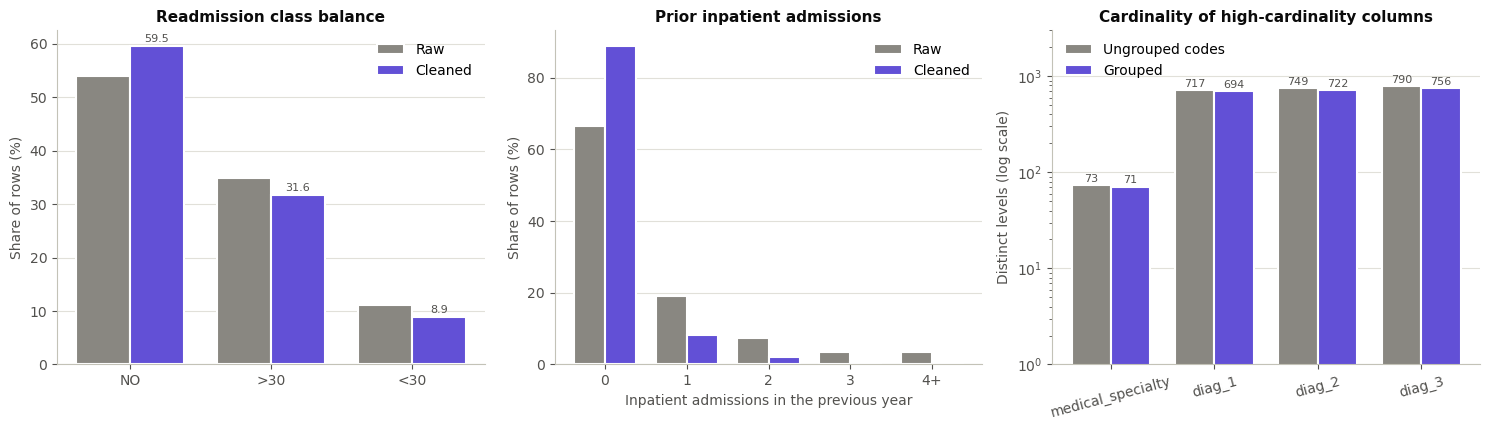

In [13]:
# %%
# ==================================================================
# 3. Before/after comparison
# ==================================================================
def count_missing_cells(frame):
    # '?', blank strings and hidden "not available" codes all count as missing
    mask = frame.isin(["?", ""]) | frame.isna()
    for col, codes in HIDDEN_MISSING_CODES.items():
        if col in frame.columns:
            mask[col] = mask[col] | frame[col].isin(list(codes))
    return int(mask.to_numpy().sum())


raw_numeric = raw_df[NUMERIC_COLUMNS].apply(pd.to_numeric)
raw_cells = raw_df.shape[0] * raw_df.shape[1]
clean_cells = df_clean.shape[0] * df_clean.shape[1]
raw_class = raw_df["readmitted"].value_counts(normalize=True) * 100
clean_class = df_clean["readmitted"].value_counts(normalize=True) * 100
unknown_cells = int(df_clean.isin(["Unknown"]).to_numpy().sum())

rows_table = [
    ("Rows (encounters)", f"{raw_df.shape[0]:,}", f"{df_clean.shape[0]:,}"),
    ("Columns", raw_df.shape[1], df_clean.shape[1]),
    ("Cells", f"{raw_cells:,}", f"{clean_cells:,}"),
    ("Distinct patients", f"{raw_df['patient_nbr'].nunique():,}",
     f"{df_clean.shape[0]:,}"),
    ("Encounters per patient (mean)",
     f"{len(raw_df) / raw_df['patient_nbr'].nunique():.2f}", "1.00"),
    ("Missing cells (incl. hidden codes)",
     f"{count_missing_cells(raw_df):,} ({count_missing_cells(raw_df) / raw_cells:.1%})",
     f"{count_missing_cells(df_clean):,} (0.0%)"),
    ("Cells in an explicit 'Unknown' category", "0",
     f"{unknown_cells:,} ({unknown_cells / clean_cells:.1%})"),
    ("Death/hospice discharges", f"{raw_df['discharge_disposition_id'].isin(list(END_OF_LIFE_CODES)).sum():,}", "0"),
]
for cls in CLASS_ORDER:
    rows_table.append((f"Readmitted {cls} (%)",
                       f"{raw_class[cls]:.2f}", f"{clean_class[cls]:.2f}"))
for col in NUMERIC_COLUMNS:
    rows_table.append((f"{col}: mean (SD)",
                       f"{raw_numeric[col].mean():.2f} ({raw_numeric[col].std():.2f})",
                       f"{df_clean[col].mean():.2f} ({df_clean[col].std():.2f})"))
rows_table.append(("Encoded model matrix (rows × columns)", "-",
                   f"{df_encoded.shape[0]:,} × {df_encoded.shape[1]}"))

before_after = pd.DataFrame(rows_table, columns=["Measure", "Raw data", "Cleaned data"])
print(before_after.to_string(index=False))

print("\nCleaning log (rows):")
print(pd.DataFrame(cleaning_log).to_string(index=False))

# ------------------------------------------------------------------
# Distribution comparison
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

x = np.arange(len(CLASS_ORDER))
width = 0.38
axes[0].bar(x - width / 2, raw_class[CLASS_ORDER], width, color=BEFORE_COLOR,
            label="Raw", edgecolor="white", linewidth=1.5)
axes[0].bar(x + width / 2, clean_class[CLASS_ORDER], width, color=AFTER_COLOR,
            label="Cleaned", edgecolor="white", linewidth=1.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(CLASS_ORDER)
axes[0].set_ylabel("Share of rows (%)")
axes[0].set_title("Readmission class balance")
for i, cls in enumerate(CLASS_ORDER):
    axes[0].text(i + width / 2, clean_class[cls] + 0.8, f"{clean_class[cls]:.1f}",
                 ha="center", fontsize=8, color=INK_2)
axes[0].legend()

bins = [-0.5, 0.5, 1.5, 2.5, 3.5, np.inf]
labels = ["0", "1", "2", "3", "4+"]
raw_inp = pd.cut(raw_numeric["number_inpatient"], bins, labels=labels).value_counts(normalize=True).reindex(labels) * 100
clean_inp = pd.cut(df_clean["number_inpatient"], bins, labels=labels).value_counts(normalize=True).reindex(labels) * 100
x = np.arange(len(labels))
axes[1].bar(x - width / 2, raw_inp, width, color=BEFORE_COLOR, label="Raw",
            edgecolor="white", linewidth=1.5)
axes[1].bar(x + width / 2, clean_inp, width, color=AFTER_COLOR, label="Cleaned",
            edgecolor="white", linewidth=1.5)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_xlabel("Inpatient admissions in the previous year")
axes[1].set_ylabel("Share of rows (%)")
axes[1].set_title("Prior inpatient admissions")
axes[1].legend()

# Cardinality comparison for high-cardinality columns
HIGH_CARD_COLUMNS = ["medical_specialty", "diag_1", "diag_2", "diag_3"]
cardinality = pd.DataFrame({
    "Column": HIGH_CARD_COLUMNS,
    "Levels before": [raw_df[col].nunique() for col in HIGH_CARD_COLUMNS],
    "Levels after":  [df_clean[col].nunique() for col in HIGH_CARD_COLUMNS],
})

x = np.arange(len(cardinality))
axes[2].bar(x - width / 2, cardinality["Levels before"], width, color=BEFORE_COLOR,
            label="Ungrouped codes", edgecolor="white", linewidth=1.5)
axes[2].bar(x + width / 2, cardinality["Levels after"], width, color=AFTER_COLOR,
            label="Grouped", edgecolor="white", linewidth=1.5)
axes[2].set_yscale("log")
axes[2].set_ylim(1, 3000)
axes[2].set_xticks(x)
axes[2].set_xticklabels(cardinality["Column"], rotation=15)
axes[2].set_ylabel("Distinct levels (log scale)")
axes[2].set_title("Cardinality of high-cardinality columns")
for i, (before, after) in enumerate(zip(cardinality["Levels before"],
                                        cardinality["Levels after"])):
    axes[2].text(i - width / 2, before * 1.08, str(before), ha="center", fontsize=8, color=INK_2)
    axes[2].text(i + width / 2, after * 1.08, str(after), ha="center", fontsize=8, color=INK_2)
axes[2].legend()

plt.tight_layout()
plt.show()

**What changed and why it matters**

* **Rows:** 101,766 encounters became 69,987 patients. 3 rows had an invalid gender, 2,423 encounters ended in death or hospice, and 29,353 were later encounters of patients already in the data. No exact duplicates and no out-of-range values were found.
* **Columns:** 50 became 34. `weight` (96% missing), 13 near-constant drug columns and the two identifiers were removed, and `admission_type_id` was replaced by the labelled `admission_type`. The cleaned table has 2.38 million cells; the encoded, model-ready matrix has 69,987 × 200 = 14.0 million cells. The raw dataset (5.09 million cells) and the model-ready matrix both meet the 3-million-cell requirement.
* **Outcome:** the early-readmission rate fell from 11.16% to 8.98%. The raw rate is inflated by repeat encounters: patients admitted many times contribute many rows and are readmitted more often. One row per patient removes this over-weighting, so the tests compare patients, not visits.
* **Prior admissions changed most:** the mean of `number_inpatient` dropped from 0.64 to 0.18, and the share of rows with no prior admission rose from 66.5% to 88.3%. Later encounters of frequent patients naturally carry many prior admissions.
* **Missing data are now explicit:** 214,992 raw cells (4.2%) were missing, as "?" or as hidden "not available" codes. After cleaning no value is missing, and 83,725 cells (3.5%) are in an explicit "Unknown" category.
* **Cardinality:** each diagnosis column went from 695–757 distinct ICD-9 codes to 20 chapters, and medical specialty from 71 levels to 11.
* **Other variables changed little** (e.g. mean length of stay 4.40 → 4.27 days, lab procedures 43.1 → 42.9), so the cleaning did not distort the stay-level variables.

In [14]:
# EDA data bridge (the plots below use df_eda and early_readmit)
df_eda = df_clean.copy()
df_eda["early_readmit"] = df_eda["readmitted"].eq("<30").astype("int8")

assert df_eda["readmitted"].isin(CLASS_ORDER).all()
assert df_eda["early_readmit"].equals(df_eda["readmitted"].eq("<30").astype("int8"))
print(f"EDA sample: {len(df_eda):,} processed patients; before encoding.")

EDA sample: 69,290 processed patients; before encoding.


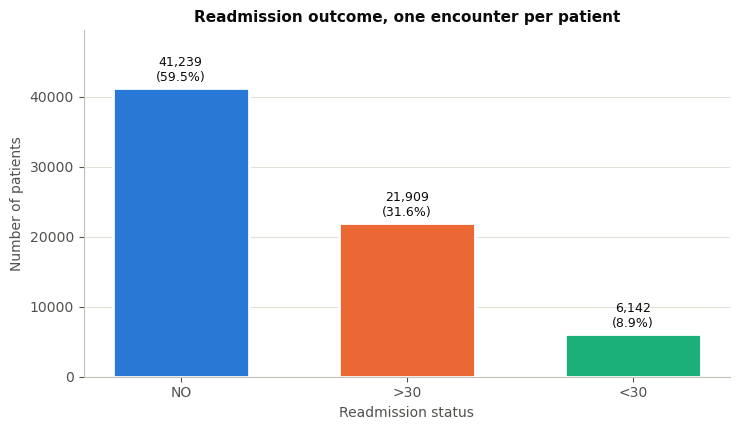

In [15]:
# %%
# EDA 1: distribution of the target
counts = df_eda["readmitted"].value_counts().reindex(CLASS_ORDER)
total = counts.sum()

fig, ax = plt.subplots(figsize=(7.5, 4.4))
bars = ax.bar(CLASS_ORDER, counts.values, width=0.6,
              color=[CLASS_COLORS[c] for c in CLASS_ORDER],
              edgecolor="white", linewidth=2)
for bar, n in zip(bars, counts.values):
    ax.annotate(f"{n:,}\n({n / total:.1%})",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=9, color=INK)
ax.set_ylim(0, counts.max() * 1.2)
ax.set_title("Readmission outcome, one encounter per patient")
ax.set_xlabel("Readmission status")
ax.set_ylabel("Number of patients")
plt.tight_layout()
plt.show()

**Observation.** Of 69,987 patients, 59.3% had no recorded readmission, 31.8% were readmitted after more than 30 days and **9.0% (6,285) within 30 days**. The outcome of interest therefore affects about 1 patient in 11. This has three consequences:

1. Every comparison in Section 5 sets about 6,300 early-readmission patients against about 63,700 others, so the groups are very unequal in size. Welch's test and Newcombe intervals handle this.
2. With about 70,000 patients even tiny differences become statistically significant. This is why each test states in advance the smallest effect that matters.
3. A future prediction model would have to deal with a 9 : 91 class imbalance.

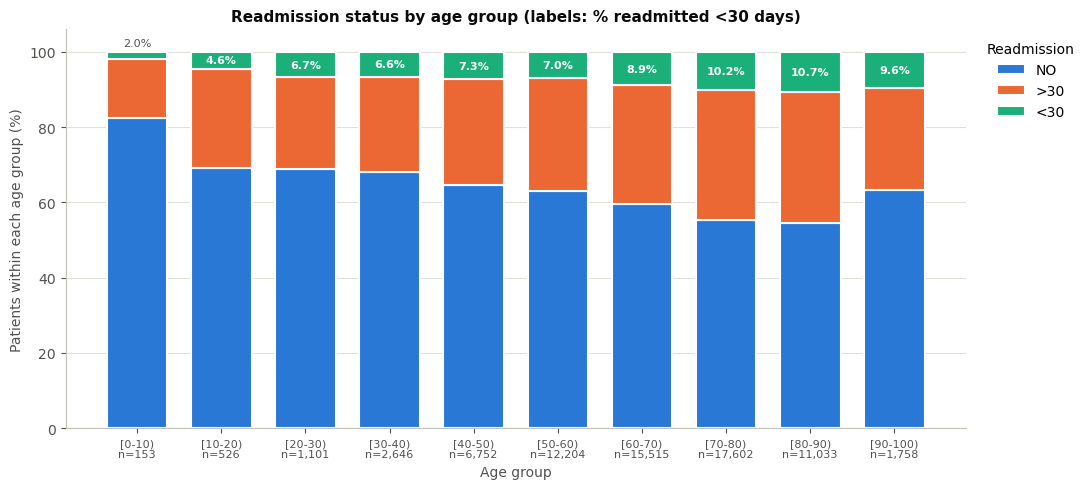

Early-readmission rate by age (95% Wilson CI):
              n  Rate %  CI low %  CI high %
age                                         
[0-10)      153    1.96      0.67       5.61
[10-20)     526    4.56      3.09       6.70
[20-30)    1101    6.72      5.39       8.36
[30-40)    2646    6.58      5.69       7.58
[40-50)    6752    7.30      6.70       7.95
[50-60)   12204    6.97      6.53       7.44
[60-70)   15515    8.91      8.47       9.37
[70-80)   17602   10.16      9.73      10.62
[80-90)   11033   10.73     10.17      11.32
[90-100)   1758    9.56      8.27      11.02


In [16]:
# %%
# EDA 2: readmission status by age group
AGE_ORDER = ["[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)",
             "[50-60)", "[60-70)", "[70-80)", "[80-90)", "[90-100)"]

age_table = (pd.crosstab(df_eda["age"], df_eda["readmitted"], normalize="index")
               .reindex(index=AGE_ORDER, columns=CLASS_ORDER) * 100)
age_n = df_eda["age"].value_counts().reindex(AGE_ORDER)

fig, ax = plt.subplots(figsize=(11, 5))
positions = np.arange(len(AGE_ORDER))
bottom = np.zeros(len(AGE_ORDER))
for cls in CLASS_ORDER:
    ax.bar(positions, age_table[cls].values, bottom=bottom, width=0.72,
           color=CLASS_COLORS[cls], label=cls, edgecolor="white", linewidth=1.5)
    bottom += age_table[cls].values
for i, value in enumerate(age_table["<30"].values):
    if value >= 4:      # label inside the segment when it is tall enough
        ax.text(i, 100 - value / 2, f"{value:.1f}%", ha="center", va="center",
                fontsize=8, color="white", fontweight="bold")
    else:               # otherwise just above the bar
        ax.text(i, 101, f"{value:.1f}%", ha="center", va="bottom",
                fontsize=8, color=INK_2)
ax.set_xticks(positions)
ax.set_xticklabels([f"{age}\nn={n:,}" for age, n in zip(AGE_ORDER, age_n)], fontsize=8)
ax.set_ylim(0, 106)
ax.set_yticks(range(0, 101, 20))
ax.set_title("Readmission status by age group (labels: % readmitted <30 days)")
ax.set_xlabel("Age group")
ax.set_ylabel("Patients within each age group (%)")
ax.legend(title="Readmission", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

age_early = df_eda.groupby("age")["early_readmit"].agg(["sum", "count"]).reindex(AGE_ORDER)
low, high = wilson_ci(age_early["sum"], age_early["count"])
print("Early-readmission rate by age (95% Wilson CI):")
print(pd.DataFrame({"n": age_early["count"],
                    "Rate %": (age_early["sum"] / age_early["count"] * 100).round(2),
                    "CI low %": (low * 100).round(2),
                    "CI high %": (high * 100).round(2)}).to_string())

**Observation.** Early readmission becomes more common with age. The rate is 2.0% in the youngest band (only 153 patients; 95% CI 0.7–5.6%) and about 7% between ages 20 and 60. It then rises to 9.0% at 60–70, 10.2% at 70–80 and a peak of 10.8% at 80–90, before easing to 9.5% at 90–100. The share with no readmission at all falls from 82% in children to about 55% at ages 70–90. Older patients also tend to have more prior admissions and longer stays, so **age is a potential confounder**. It is included as an adjustment variable in Test 5.

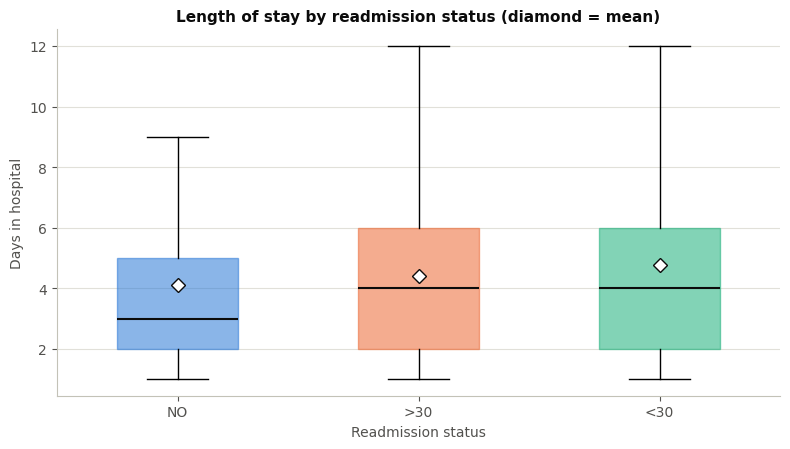

            count   mean  median    std
readmitted                             
NO          41239  4.093     3.0  2.855
>30         21909  4.397     4.0  2.944
<30          6142  4.752     4.0  3.010


In [17]:
# %%
# EDA 3: length of stay by readmission status
los_by_class = [df_eda.loc[df_eda["readmitted"] == cls, "time_in_hospital"]
                for cls in CLASS_ORDER]

fig, ax = plt.subplots(figsize=(8, 4.6))
box = ax.boxplot(los_by_class, positions=[1, 2, 3], widths=0.5, showfliers=False,
                 patch_artist=True, showmeans=True,
                 medianprops=dict(color=INK, linewidth=1.5),
                 meanprops=dict(marker="D", markerfacecolor="white",
                                markeredgecolor=INK, markersize=7))
for patch, cls in zip(box["boxes"], CLASS_ORDER):
    patch.set_facecolor(CLASS_COLORS[cls])
    patch.set_alpha(0.55)
    patch.set_edgecolor(CLASS_COLORS[cls])
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(CLASS_ORDER)
ax.set_title("Length of stay by readmission status (diamond = mean)")
ax.set_xlabel("Readmission status")
ax.set_ylabel("Days in hospital")
plt.tight_layout()
plt.show()

print(df_eda.groupby("readmitted")["time_in_hospital"]
      .agg(["count", "mean", "median", "std"]).reindex(CLASS_ORDER).round(3).to_string())

**Observation.** The median stay is 3 days for "NO" and 4 days for both readmitted groups. The means rise in the same order: 4.12, 4.42 and 4.80 days. The "<30" group has the widest middle 50% (2–7 days), and its upper whisker reaches the 14-day maximum. All three distributions are right-skewed (mean above median) and overlap heavily, with an SD of about 3 days in each group.

"Overlapping distributions" and "different means" are not contradictory: a shift of about half a day is small compared with a 3-day spread, yet it can be estimated precisely with 70,000 patients. Test 3 therefore asks whether the mean difference is large enough to matter, not only whether it exists.

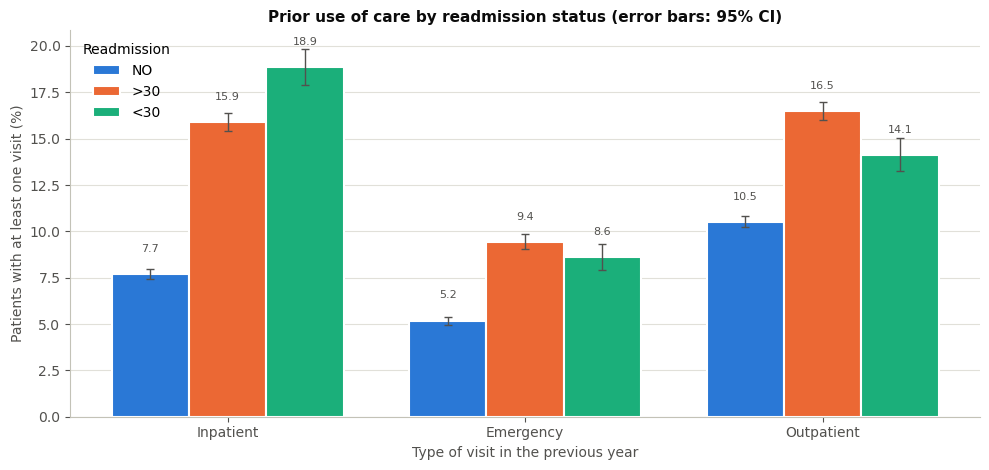

Visit type Readmission     n  % with >= 1 visit  CI low  CI high
 Inpatient          NO 41239               7.71    7.45     7.97
 Inpatient         >30 21909              15.88   15.40    16.37
 Inpatient         <30  6142              18.85   17.90    19.85
 Emergency          NO 41239               5.18    4.97     5.40
 Emergency         >30 21909               9.44    9.06     9.83
 Emergency         <30  6142               8.61    7.94     9.34
Outpatient          NO 41239              10.50   10.21    10.80
Outpatient         >30 21909              16.49   16.01    16.99
Outpatient         <30  6142              14.12   13.27    15.01

Dispersion of prior-visit counts (a Poisson variable has variance = mean):
           Column  Mean  Variance  Variance / mean  % zeros observed  % zeros if Poisson
 number_inpatient 0.157     0.260            1.654            88.721              85.482
 number_emergency 0.086     0.124            1.440            93.169              91.741
number_

In [18]:
# %%
# EDA 4: prior use of care by readmission status.
# These counts are zero for most patients, so box plots collapse to zero.
# We show the share of patients with at least one visit instead.
VISIT_COLUMNS = {"number_inpatient": "Inpatient", "number_emergency": "Emergency",
                 "number_outpatient": "Outpatient"}

rows = []
for col, label in VISIT_COLUMNS.items():
    for cls in CLASS_ORDER:
        sub = df_eda.loc[df_eda["readmitted"] == cls, col]
        k, n = int((sub > 0).sum()), len(sub)
        low, high = wilson_ci(k, n)
        rows.append({"Visit type": label, "Readmission": cls, "n": n,
                     "% with >= 1 visit": 100 * k / n,
                     "CI low": 100 * float(low), "CI high": 100 * float(high)})
visit_table = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4.8))
width = 0.26
x = np.arange(len(VISIT_COLUMNS))
for j, cls in enumerate(CLASS_ORDER):
    sub = visit_table[visit_table["Readmission"] == cls]
    values = sub["% with >= 1 visit"].values
    errors = np.vstack([values - sub["CI low"].values, sub["CI high"].values - values])
    ax.bar(x + (j - 1) * width, values, width, yerr=errors, capsize=3,
           color=CLASS_COLORS[cls], label=cls, edgecolor="white", linewidth=1.5,
           error_kw=dict(ecolor=INK_2, elinewidth=1))
    for xi, v in zip(x + (j - 1) * width, values):
        ax.text(xi, v + 1.2, f"{v:.1f}", ha="center", fontsize=8, color=INK_2)
ax.set_xticks(x)
ax.set_xticklabels(list(VISIT_COLUMNS.values()))
ax.set_xlabel("Type of visit in the previous year")
ax.set_ylabel("Patients with at least one visit (%)")
ax.set_title("Prior use of care by readmission status (error bars: 95% CI)")
ax.legend(title="Readmission")
plt.tight_layout()
plt.show()

print(visit_table.round(2).to_string(index=False))

# Over-dispersion check (descriptive, replaces a Poisson goodness-of-fit test)
print("\nDispersion of prior-visit counts (a Poisson variable has variance = mean):")
dispersion = []
for col in VISIT_COLUMNS:
    s = df_eda[col]
    dispersion.append({"Column": col, "Mean": s.mean(), "Variance": s.var(),
                       "Variance / mean": s.var() / s.mean(),
                       "% zeros observed": 100 * (s == 0).mean(),
                       "% zeros if Poisson": 100 * np.exp(-s.mean())})
print(pd.DataFrame(dispersion).round(3).to_string(index=False))

**Observation.** Most patients had no prior visits: 88% had no inpatient admission, 93% no emergency visit and 87% no outpatient visit. Box plots of these counts collapse onto zero, so the chart shows the share of patients with at least one visit instead.

* **Prior inpatient admissions separate the three groups clearly and in order:** 7.8% of "NO", 16.6% of ">30" and 20.1% of "<30" patients had at least one, and the CIs do not overlap.
* Emergency and outpatient visits separate "NO" from the two readmitted groups, but not "<30" from ">30". Emergency visits are 9.8% vs 10.2% with overlapping CIs, and outpatient visits are actually *less* common in "<30" (14.8%) than in ">30" (17.0%). This is why Problem 1 focuses on `number_inpatient`.
* **Dispersion table:** for every count the variance is 2–4 times the mean, and there are more zeros than a Poisson distribution would predict (88.3% vs 83.8% for inpatient admissions). This over-dispersion is documented descriptively here instead of with a Poisson goodness-of-fit test. It is also why Tests 1 and 2 use categories (0 / 1 / 2+) rather than a test of mean counts.

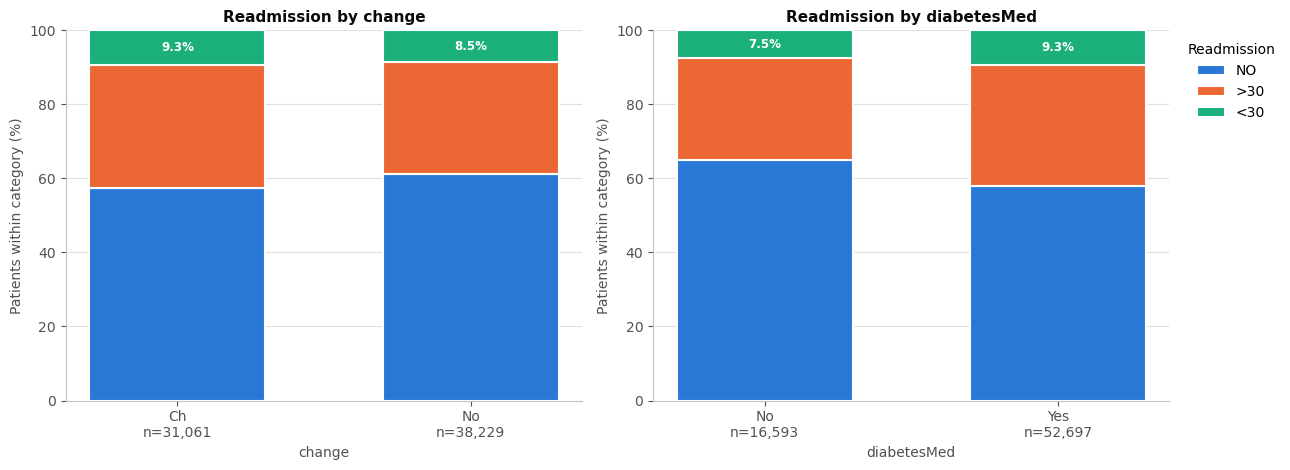

Strength of association (descriptive):
  change       Cramér's V (3 classes) = 0.037 | V (early vs not) = 0.014 | early-readmission % = {'Ch': 9.31, 'No': 8.5}
  diabetesMed  Cramér's V (3 classes) = 0.061 | V (early vs not) = 0.028 | early-readmission % = {'No': 7.46, 'Yes': 9.31}
  insulin      Cramér's V (3 classes) = 0.033 | V (early vs not) = 0.025 | early-readmission % = {'Down': 10.4, 'No': 8.22, 'Steady': 9.14, 'Up': 9.6}


In [19]:
# %%
# EDA 5: medication management (change, diabetesMed) and readmission
medication_cols = ["change", "diabetesMed"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, col in zip(axes, medication_cols):
    table = pd.crosstab(df_eda[col], df_eda["readmitted"], normalize="index")[CLASS_ORDER] * 100
    positions = np.arange(len(table))
    bottom = np.zeros(len(table))
    for cls in CLASS_ORDER:
        ax.bar(positions, table[cls].values, bottom=bottom, width=0.6,
               color=CLASS_COLORS[cls], label=cls, edgecolor="white", linewidth=1.5)
        bottom += table[cls].values
    for i, value in enumerate(table["<30"].values):
        ax.text(i, 100 - value / 2, f"{value:.1f}%", ha="center", va="center",
                fontsize=8.5, color="white", fontweight="bold")
    counts = df_eda[col].value_counts().reindex(table.index)
    ax.set_xticks(positions)
    ax.set_xticklabels([f"{v}\nn={n:,}" for v, n in zip(table.index, counts)])
    ax.set_ylim(0, 100)
    ax.set_title(f"Readmission by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Patients within category (%)")
axes[1].legend(title="Readmission", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("Strength of association (descriptive):")
for col in medication_cols + ["insulin"]:
    v3 = cramers_v(pd.crosstab(df_eda[col], df_eda["readmitted"]))
    v2 = cramers_v(pd.crosstab(df_eda[col], df_eda["early_readmit"]))
    rates = df_eda.groupby(col)["early_readmit"].mean().mul(100).round(2).to_dict()
    print(f"  {col:<12} Cramér's V (3 classes) = {v3:.3f} | "
          f"V (early vs not) = {v2:.3f} | early-readmission % = {rates}")

**Observation.** The early-readmission rate differs only slightly between groups:

* 9.4% with a medication change vs 8.6% without.
* 9.4% with any diabetes drug vs 7.6% without.
* By insulin category: 8.3% (no insulin), 9.3% (steady), 9.8% (dose increased) and 10.5% (dose decreased).

All Cramér's V values are at most 0.061 for the three-class outcome and 0.015–0.028 for early vs not early. They are far below 0.10, the conventional threshold for even a "small" association. The stacked bars therefore look *similar*, because the differences are only 1–2 percentage points. With about 70,000 patients, differences of this size can still be statistically *significant*. The two statements are not contradictory: "similar" describes the size, "significant" only says the difference is unlikely to be exactly zero. Test 5 quantifies this for insulin and checks whether the difference remains after adjustment.

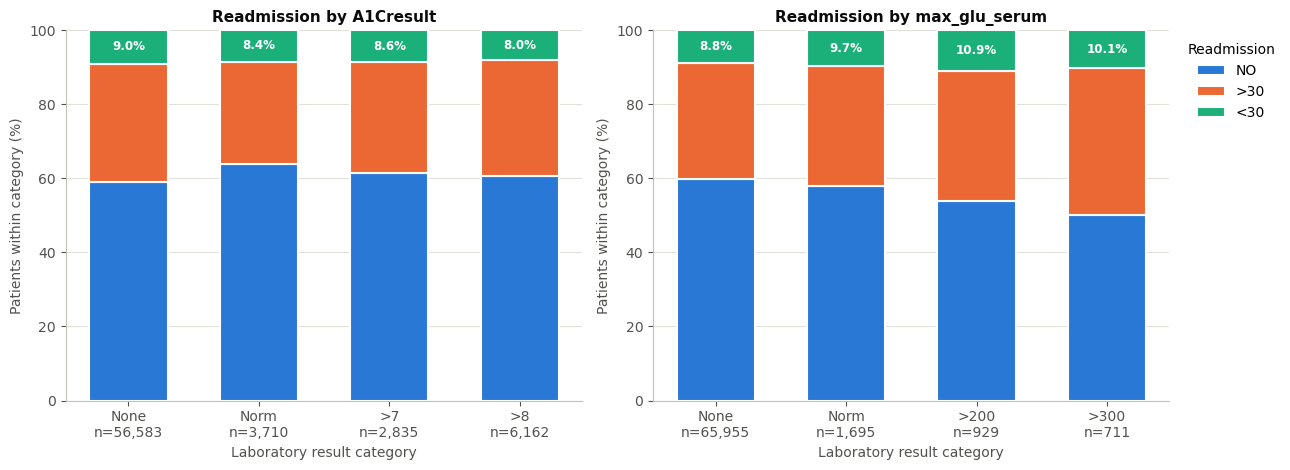

A1Cresult: early-readmission % (95% CI)
   None   9.00  (8.76-9.24), n = 56,583
   Norm   8.44  (7.58-9.37), n = 3,710
   >7     8.57  (7.60-9.66), n = 2,835
   >8     8.03  (7.38-8.74), n = 6,162
max_glu_serum: early-readmission % (95% CI)
   None   8.80  (8.59-9.02), n = 65,955
   Norm   9.73  (8.41-11.24), n = 1,695
   >200  10.87  (9.03-13.04), n = 929
   >300  10.13  (8.12-12.56), n = 711


In [20]:
# %%
# EDA 6: laboratory results and readmission
LAB_ORDERS = {"A1Cresult": ["None", "Norm", ">7", ">8"],
              "max_glu_serum": ["None", "Norm", ">200", ">300"]}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (col, order) in zip(axes, LAB_ORDERS.items()):
    table = (pd.crosstab(df_eda[col], df_eda["readmitted"], normalize="index")
               .reindex(index=order, columns=CLASS_ORDER) * 100)
    counts = df_eda[col].value_counts().reindex(order)
    positions = np.arange(len(order))
    bottom = np.zeros(len(order))
    for cls in CLASS_ORDER:
        ax.bar(positions, table[cls].values, bottom=bottom, width=0.6,
               color=CLASS_COLORS[cls], label=cls, edgecolor="white", linewidth=1.5)
        bottom += table[cls].values
    for i, value in enumerate(table["<30"].values):
        ax.text(i, 100 - value / 2, f"{value:.1f}%", ha="center", va="center",
                fontsize=8.5, color="white", fontweight="bold")
    ax.set_xticks(positions)
    ax.set_xticklabels([f"{v}\nn={n:,}" for v, n in zip(order, counts)])
    ax.set_ylim(0, 100)
    ax.set_title(f"Readmission by {col}")
    ax.set_xlabel("Laboratory result category")
    ax.set_ylabel("Patients within category (%)")
axes[1].legend(title="Readmission", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

for col, order in LAB_ORDERS.items():
    grouped = df_eda.groupby(col)["early_readmit"].agg(["sum", "count"]).reindex(order)
    low, high = wilson_ci(grouped["sum"], grouped["count"])
    print(f"{col}: early-readmission % (95% CI)")
    for level, s, n, lo, hi in zip(order, grouped["sum"], grouped["count"], low, high):
        print(f"   {level:<5} {100 * s / n:5.2f}  ({100 * lo:.2f}-{100 * hi:.2f}), n = {n:,}")

**Observation.** HbA1c was not measured for 82% of patients (57,141) and maximum serum glucose for 95% (66,638). Early-readmission rates are close across the HbA1c categories (8.2–9.1%, overlapping CIs). Patients with a measured glucose value have slightly higher rates (9.8–10.9%) than those without (8.9%), but these groups are small (712–1,701 patients) and their CIs overlap with each other. Neither laboratory variable shows a clear, sizeable difference, so neither is used as a primary test variable.

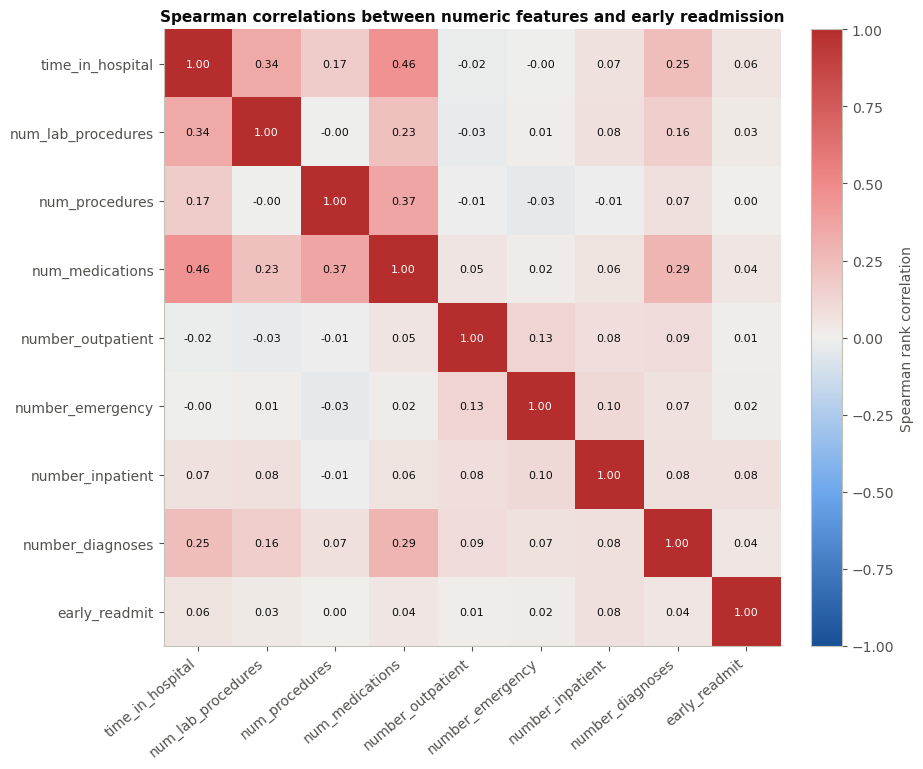

Spearman correlation with early readmission:
number_inpatient      0.077
time_in_hospital      0.059
number_diagnoses      0.042
num_medications       0.042
num_lab_procedures    0.031
number_emergency      0.022
number_outpatient     0.013
num_procedures        0.002


In [21]:
# %%
# EDA 7: Spearman rank correlations (counts are skewed and tied, so ranks
# are more appropriate than Pearson); the outcome is included as a 0/1 column.
corr_columns = NUMERIC_COLUMNS + ["early_readmit"]
correlation = df_eda[corr_columns].corr(method="spearman")

diverging = LinearSegmentedColormap.from_list(
    "blue_gray_red", ["#184f95", "#6da7ec", "#f0efec", "#ef8a89", "#b52e2d"])

fig, ax = plt.subplots(figsize=(9.5, 7.8))
image = ax.imshow(correlation.values, cmap=diverging, vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(corr_columns)))
ax.set_yticks(range(len(corr_columns)))
ax.set_xticklabels(corr_columns, rotation=40, ha="right")
ax.set_yticklabels(corr_columns)
for i in range(len(corr_columns)):
    for j in range(len(corr_columns)):
        value = correlation.values[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.6 else INK)
colorbar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
colorbar.set_label("Spearman rank correlation")
ax.set_title("Spearman correlations between numeric features and early readmission")
plt.tight_layout()
plt.show()

print("Spearman correlation with early readmission:")
print(correlation["early_readmit"].drop("early_readmit")
      .sort_values(ascending=False).round(3).to_string())

**Observation.** Spearman (rank) correlations are used because the counts are skewed and heavily tied; Pearson's r assumes linear relationships between roughly symmetric variables.

* The strongest relationships are among in-hospital workload variables: length of stay with number of medications ($\rho = 0.46$), procedures with medications (0.37), and length of stay with lab procedures (0.35).
* The three prior-visit counts are only weakly related to each other (0.10–0.15) and almost unrelated to in-hospital workload.
* Every correlation with early readmission is small. The largest is 0.085 for `number_inpatient`, followed by 0.060 for length of stay.

No single numeric variable separates early readmission on its own. No pair is so strongly correlated (all $|\rho| < 0.5$) that it would cause collinearity problems in the adjusted model of Test 5.

# 5. Statistical inference — hypothesis tests on processed data

This section leaves the EDA above intact and uses `df_clean`, the readable processed table created in Section 2 **before encoding**. It therefore uses the same patient-level, cleaned analysis sample as the EDA rather than the raw encounter-level data or `df_encoded`. The categorical variables remain labels (`NO`, `>30`, `<30`; `Ch`, `No`; and `No`, `Steady`, `Up`, `Down`).

The nine candidate tests below preserve the research questions and compare test choices, effect sizes, and confidence intervals. The course report asks for 3–5 formal tests, so select the most defensible subset for the final report; the others can be supplementary analysis.

## 5.1 Shared statistical helpers and constants

The significance level is fixed at 0.05. The effect-size thresholds below are practical benchmarks to declare before interpreting results; they are not supplied by the dataset itself, so explain and justify them in the report.

In [22]:
import warnings

import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import poisson

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)

ALPHA = 0.05
SEED = 20261019
CLASS_ORDER = ["NO", ">30", "<30"]
NUMERIC_COLUMNS = [
    "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses",
]
BINARY_COLUMNS = ["change", "diabetesMed"]


def format_p(p):
    """Format tiny p-values without printing an underflowed zero."""
    if not np.isfinite(p):
        return "not available"
    if p < 1e-300:
        return "< 1e-300"
    if p < 0.001:
        return f"{p:.3e}"
    return f"{p:.4f}"


def wilson_interval(successes, n, confidence=0.95):
    """Wilson score CI for a binomial proportion."""
    if n <= 0:
        raise ValueError("A proportion interval requires n > 0.")
    z = stats.norm.ppf(0.5 + confidence / 2)
    p = successes / n
    den = 1 + z**2 / n
    centre = (p + z**2 / (2*n)) / den
    half = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / den
    return float(centre - half), float(centre + half)


def newcombe_diff_ci(x1, n1, x2, n2, confidence=0.95):
    """Newcombe score CI for p1 - p2, based on two Wilson intervals."""
    p1, p2 = x1 / n1, x2 / n2
    lo1, hi1 = wilson_interval(x1, n1, confidence)
    lo2, hi2 = wilson_interval(x2, n2, confidence)
    difference = p1 - p2
    lower = difference - np.sqrt((p1 - lo1)**2 + (hi2 - p2)**2)
    upper = difference + np.sqrt((hi1 - p1)**2 + (p2 - lo2)**2)
    return float(difference), float(lower), float(upper)


def cramers_v_from_table(table):
    """Cramer's V with Pearson's chi-square statistic (no Yates correction)."""
    observed = np.asarray(table, dtype=float)
    n = observed.sum()
    if n <= 0 or min(observed.shape) < 2:
        return np.nan
    expected = np.outer(observed.sum(axis=1), observed.sum(axis=0)) / n
    if (expected <= 0).any():
        return np.nan
    chi2_value = np.sum((observed - expected)**2 / expected)
    return float(np.sqrt(chi2_value / (n * min(observed.shape[0] - 1, observed.shape[1] - 1))))


def bootstrap_cramers_v(frame, row_col, col_col, row_order, col_order,
                        iterations=500, seed=SEED):
    """Nonparametric row bootstrap CI for Cramer's V; deterministic seed."""
    row_codes = pd.Categorical(frame[row_col], categories=row_order).codes
    col_codes = pd.Categorical(frame[col_col], categories=col_order).codes
    if (row_codes < 0).any() or (col_codes < 0).any():
        raise ValueError(f"Unexpected/missing categories in {row_col} or {col_col}.")
    n = len(frame)
    nr, nc = len(row_order), len(col_order)
    base = np.bincount(row_codes * nc + col_codes, minlength=nr*nc).reshape(nr, nc)
    point = cramers_v_from_table(base)
    rng = np.random.default_rng(seed)
    boot = []
    for _ in range(iterations):
        idx = rng.integers(0, n, size=n)
        tab = np.bincount(row_codes[idx] * nc + col_codes[idx], minlength=nr*nc).reshape(nr, nc)
        value = cramers_v_from_table(tab)
        if np.isfinite(value):
            boot.append(value)
    if len(boot) < iterations * 0.95:
        warnings.warn(f"Many bootstrap replicates were invalid for {row_col} vs {col_col}.")
    lo, hi = np.quantile(boot, [0.025, 0.975])
    return point, float(lo), float(hi), base


def benjamini_hochberg(p_values):
    """Benjamini-Hochberg false-discovery-rate adjusted p-values."""
    p = np.asarray(p_values, dtype=float)
    m = len(p)
    order = np.argsort(p)
    ranked = p[order] * m / np.arange(1, m + 1)
    adjusted_sorted = np.minimum.accumulate(ranked[::-1])[::-1]
    adjusted = np.empty(m, dtype=float)
    adjusted[order] = np.minimum(adjusted_sorted, 1.0)
    return adjusted


results = []
print("Libraries loaded; alpha =", ALPHA, "| random seed =", SEED)

Libraries loaded; alpha = 0.05 | random seed = 20261019


## 5.1 Connect the tests to the EDA's processed data

No dataset is reloaded or cleaned in this section. `df_test` is a copy of `df_clean` from the EDA pipeline. The checks below fail early if any test column is missing, if outcome labels differ from the EDA's three classes, or if the fields used by the tests still contain missing values.

In [23]:
# Use the exact processed sample constructed by pre_fin_final.ipynb.
if "df_clean" not in globals():
    raise NameError("df_clean is unavailable. Run the EDA/preprocessing cells first.")

df_test = df_clean.copy()
required_test_columns = [
    "readmitted", "number_inpatient", "time_in_hospital",
    "num_lab_procedures", "num_medications", "change",
    "insulin", "diabetesMed",
]
missing_columns = [c for c in required_test_columns if c not in df_test.columns]
if missing_columns:
    raise KeyError(f"Processed df_clean is missing required test columns: {missing_columns}")

unexpected_outcomes = set(df_test["readmitted"].dropna().unique()) - set(CLASS_ORDER)
if unexpected_outcomes:
    raise ValueError(f"Unexpected readmission labels in df_clean: {unexpected_outcomes}")
missing_test_values = df_test[required_test_columns].isna().sum()
if missing_test_values.any():
    raise ValueError("Missing values remain in test columns:\n" + missing_test_values[missing_test_values > 0].to_string())

print("Processed-data alignment check")
print(f"Rows in df_clean / df_test: {len(df_clean):,} / {len(df_test):,}")
if "n_before_pca" in globals() and "outlier_mask" in globals():
    print(f"Patients before PCA/Isolation Forest screen: {n_before_pca:,}")
    print(f"Rows removed by that screen: {int(np.asarray(outlier_mask).sum()):,}")
print("Columns checked:", ", ".join(required_test_columns))
print("Readmission counts:")
print(df_test["readmitted"].value_counts().reindex(CLASS_ORDER, fill_value=0).to_string())
assert df_test.equals(df_clean), "df_test must be an exact copy of df_clean."

Processed-data alignment check
Rows in df_clean / df_test: 69,290 / 69,290
Patients before PCA/Isolation Forest screen: 69,990
Rows removed by that screen: 700
Columns checked: readmitted, number_inpatient, time_in_hospital, num_lab_procedures, num_medications, change, insulin, diabetesMed
Readmission counts:
readmitted
NO     41239
>30    21909
<30     6142


## Problem 1 — Can previous healthcare utilization help identify early readmission?

### Test 1. Poisson goodness-of-fit for previous inpatient admissions

**Research question.** Does `number_inpatient` follow a Poisson distribution with its rate estimated from the processed sample?

- **H₀:** `number_inpatient` follows the fitted Poisson distribution.
- **H₁:** Its distribution differs from the fitted Poisson distribution.
- **α:** 0.05; two-sided goodness-of-fit test.
- **Primary test:** Pearson chi-square goodness-of-fit using categories `0`, `1`, and `2+`. The tail is combined because a Poisson model with the small processed mean can otherwise produce expected counts below 5.
- **Practical threshold:** Cohen's goodness-of-fit effect size, *w* = 0.10 (conventional small-effect benchmark); report the estimate and bootstrap 95% CI.
- **Alternatives considered:** A Kolmogorov–Smirnov test is not ideal for a discrete count distribution with a parameter estimated from the same data. A parametric-bootstrap goodness-of-fit test would be a useful sensitivity check if expected counts are sparse; here the categories are combined to keep expected counts adequate. A negative-binomial model allows over-dispersion but answers a different model-choice question.

In [24]:
x = df_test["number_inpatient"].astype(int).to_numpy()
if (x < 0).any():
    raise ValueError("number_inpatient must be non-negative.")
n = len(x)
lambda_hat = float(x.mean())
if lambda_hat <= 0:
    raise ValueError("The fitted Poisson rate is zero; goodness-of-fit test is not identifiable.")

observed = np.array([(x == 0).sum(), (x == 1).sum(), (x >= 2).sum()], dtype=float)
probabilities = np.array([poisson.pmf(0, lambda_hat), poisson.pmf(1, lambda_hat), poisson.sf(1, lambda_hat)])
expected = n * probabilities
expected[-1] += n - expected.sum()  # remove floating point total discrepancy
if (expected < 5).any():
    warnings.warn("An expected cell count is below 5; interpret the Pearson approximation cautiously.")
chi2_gof = float(np.sum((observed - expected)**2 / expected))
df_gof = len(observed) - 1 - 1  # categories - 1 - one estimated parameter
p_gof = float(stats.chi2.sf(chi2_gof, df_gof))
cohen_w = float(np.sqrt(chi2_gof / n))

# 95% t interval for the estimated mean/rate.
se_lambda = x.std(ddof=1) / np.sqrt(n)
tcrit_lambda = stats.t.ppf(0.975, n - 1)
lambda_ci = (lambda_hat - tcrit_lambda * se_lambda, lambda_hat + tcrit_lambda * se_lambda)

# Bootstrap CI for the goodness-of-fit effect size; refit lambda in every sample.
rng = np.random.default_rng(SEED + 1)
w_boot = []
for _ in range(500):
    xb = rng.choice(x, size=n, replace=True)
    lb = float(xb.mean())
    if lb <= 0:
        continue
    ob = np.array([(xb == 0).sum(), (xb == 1).sum(), (xb >= 2).sum()], dtype=float)
    pb = np.array([poisson.pmf(0, lb), poisson.pmf(1, lb), poisson.sf(1, lb)])
    eb = len(xb) * pb
    eb[-1] += len(xb) - eb.sum()
    if (eb > 0).all():
        w_boot.append(float(np.sqrt(np.sum((ob - eb)**2 / eb) / len(xb))))
w_ci = tuple(np.quantile(w_boot, [0.025, 0.975]))

print("TEST 1 — Poisson goodness-of-fit")
print(f"n = {n:,}; fitted lambda = {lambda_hat:.5f}; 95% CI for lambda = [{lambda_ci[0]:.5f}, {lambda_ci[1]:.5f}]")
print(pd.DataFrame({"Category": ["0", "1", "2+"], "Observed": observed.astype(int), "Expected under fitted Poisson": expected}).to_string(index=False))
print(f"Chi-square = {chi2_gof:.4f}; df = {df_gof}; p = {format_p(p_gof)}")
print(f"Cohen's w = {cohen_w:.4f}; bootstrap 95% CI = [{w_ci[0]:.4f}, {w_ci[1]:.4f}]")
print("Decision:", "Reject H0" if p_gof < ALPHA else "Fail to reject H0")
print("Practical size:", "at/above w = 0.10 benchmark" if cohen_w >= 0.10 else "below w = 0.10 benchmark")
results.append({"Test": "1. Poisson goodness-of-fit", "Statistic": f"chi-square = {chi2_gof:.4f}", "df": str(df_gof), "p_value": p_gof, "Estimate (95% CI)": f"lambda {lambda_hat:.4f} [{lambda_ci[0]:.4f}, {lambda_ci[1]:.4f}]; w {cohen_w:.4f} [{w_ci[0]:.4f}, {w_ci[1]:.4f}]", "Practical threshold": "Cohen's w >= 0.10", "Meaningful by point estimate?": cohen_w >= 0.10, "Decision": "Reject H0" if p_gof < ALPHA else "Fail to reject H0"})

TEST 1 — Poisson goodness-of-fit
n = 69,290; fitted lambda = 0.15686; 95% CI for lambda = [0.15307, 0.16066]
Category  Observed  Expected under fitted Poisson
       0     61475                   59230.590125
       1      5719                    9291.056200
      2+      2096                     768.353675
Chi-square = 3752.4199; df = 1; p = < 1e-300
Cohen's w = 0.2327; bootstrap 95% CI = [0.2245, 0.2414]
Decision: Reject H0
Practical size: at/above w = 0.10 benchmark


### Test 2. Two-proportion z-test: previous inpatient admission in `<30` versus `NO`

- **H₀:** \(p_{<30} = p_{NO}\) (the one-sided test is evaluated at the equality boundary).
- **H₁:** \(p_{<30} > p_{NO}\).
- **α:** 0.05; one-sided (right tail).
- **Primary test:** pooled two-proportion z-test for whether a patient had at least one inpatient admission in the previous year (`number_inpatient > 0`). Only `<30` and `NO` readmission groups enter this comparison; `>30` is excluded by the stated question.
- **Smallest meaningful difference:** 5 percentage points in the proportions.
- **Alternatives considered:** Fisher's exact test is valid but unnecessary for these large groups and is naturally reported as an exact test of a 2×2 table; Pearson's chi-square is a two-sided equivalent for a 2×2 table and does not encode the directional alternative as directly. Logistic regression could adjust for covariates but answers an adjusted, different question.

In [25]:
test2 = df_test.loc[df_test["readmitted"].isin(["<30", "NO"]), ["number_inpatient", "readmitted"]].copy()
test2["previous_inpatient"] = test2["number_inpatient"].astype(float) > 0
early = test2.loc[test2["readmitted"] == "<30", "previous_inpatient"]
no_readmit = test2.loc[test2["readmitted"] == "NO", "previous_inpatient"]
x1, n1 = int(early.sum()), len(early)
x2, n2 = int(no_readmit.sum()), len(no_readmit)
p1, p2 = x1 / n1, x2 / n2
pooled = (x1 + x2) / (n1 + n2)
se_null = np.sqrt(pooled * (1 - pooled) * (1/n1 + 1/n2))
z_stat = (p1 - p2) / se_null
p_prop = float(stats.norm.sf(z_stat))
difference, diff_lo, diff_hi = newcombe_diff_ci(x1, n1, x2, n2)
print("TEST 2 — One-sided two-proportion z-test")
print(f"<30: {x1:,}/{n1:,} = {p1:.3%}; NO: {x2:,}/{n2:,} = {p2:.3%}")
print(f"Difference p_<30 - p_NO = {difference:.3%}; 95% CI [{diff_lo:.3%}, {diff_hi:.3%}]")
print(f"z = {z_stat:.4f}; df: not applicable for z; p = {format_p(p_prop)}")
print("Decision:", "Reject H0" if p_prop < ALPHA else "Fail to reject H0")
print("Practical size:", "at/above 5 percentage-point threshold" if difference >= 0.05 else "below 5 percentage-point threshold")
results.append({"Test": "2. Prior inpatient use: <30 vs NO", "Statistic": f"z = {z_stat:.4f}", "df": "not applicable (z test)", "p_value": p_prop, "Estimate (95% CI)": f"difference {difference:.4%} [{diff_lo:.4%}, {diff_hi:.4%}]", "Practical threshold": "5 percentage points", "Meaningful by point estimate?": difference >= 0.05, "Decision": "Reject H0" if p_prop < ALPHA else "Fail to reject H0"})

TEST 2 — One-sided two-proportion z-test
<30: 1,158/6,142 = 18.854%; NO: 3,178/41,239 = 7.706%
Difference p_<30 - p_NO = 11.147%; 95% CI [10.154%, 12.177%]
z = 28.2672; df: not applicable for z; p = 4.378e-176
Decision: Reject H0
Practical size: at/above 5 percentage-point threshold


### Test 3. Chi-square test: inpatient-utilization category versus all three readmission outcomes

- **H₀:** Categorized `number_inpatient` and `readmitted` are independent.
- **H₁:** They are associated.
- **α:** 0.05; two-sided test of independence.
- **Primary test:** Pearson chi-square on `0`, `1`, and `2+` prior inpatient admissions versus `NO`, `>30`, and `<30`; report Cramér's V and a row-bootstrap 95% CI.
- **Smallest meaningful association:** Cramér's V = 0.10 (conventional small-effect benchmark).
- **Alternatives considered:** A trend test could be more powerful if a monotone ordering is assumed, but it can miss non-monotone differences across the three outcomes. Multinomial logistic regression could adjust for other patient features, but it is a different adjusted question. If any expected cell count is below 5, use an exact/Monte Carlo contingency-table test instead of relying only on the chi-square approximation.

In [26]:
test3 = df_test[["number_inpatient", "readmitted"]].copy()
test3["inpatient_group"] = np.select(
    [test3["number_inpatient"].astype(int).eq(0), test3["number_inpatient"].astype(int).eq(1)],
    ["0", "1"], default="2+"
)
row_order = ["0", "1", "2+"]
contingency = pd.crosstab(test3["inpatient_group"], test3["readmitted"]).reindex(index=row_order, columns=CLASS_ORDER, fill_value=0)
chi2_3, p_3, df_3, exp_3 = stats.chi2_contingency(contingency, correction=False)
v3, v3_lo, v3_hi, _ = bootstrap_cramers_v(test3, "inpatient_group", "readmitted", row_order, CLASS_ORDER, seed=SEED + 3)
print("TEST 3 — Chi-square test of independence")
print(contingency.to_string())
print(f"Chi-square = {chi2_3:.4f}; df = {df_3}; p = {format_p(p_3)}; minimum expected count = {exp_3.min():.2f}")
print(f"Cramer's V = {v3:.4f}; bootstrap 95% CI = [{v3_lo:.4f}, {v3_hi:.4f}]")
print("Decision:", "Reject H0" if p_3 < ALPHA else "Fail to reject H0")
print("Practical size:", "at/above V = 0.10 benchmark" if v3 >= 0.10 else "below V = 0.10 benchmark")
results.append({"Test": "3. Inpatient category × readmission", "Statistic": f"chi-square = {chi2_3:.4f}", "df": str(df_3), "p_value": float(p_3), "Estimate (95% CI)": f"Cramer's V {v3:.4f} [{v3_lo:.4f}, {v3_hi:.4f}]", "Practical threshold": "Cramer's V >= 0.10", "Meaningful by point estimate?": v3 >= 0.10, "Decision": "Reject H0" if p_3 < ALPHA else "Fail to reject H0"})

TEST 3 — Chi-square test of independence
readmitted          NO    >30   <30
inpatient_group                    
0                38061  18430  4984
1                 2537   2451   731
2+                 641   1028   427
Chi-square = 1508.7669; df = 4; p = < 1e-300; minimum expected count = 185.79
Cramer's V = 0.1043; bootstrap 95% CI = [0.0993, 0.1097]
Decision: Reject H0
Practical size: at/above V = 0.10 benchmark


## Problem 2 — Does hospital resource intensity differ by readmission status?

### Test 4. Welch two-sample t-test for hospital-stay duration (`<30` versus `NO`)

- **H₀:** \(\mu_{<30} = \mu_{NO}\).
- **H₁:** \(\mu_{<30} \ne \mu_{NO}\).
- **α:** 0.05; two-sided.
- **Primary test:** Welch's independent two-sample t-test; it does not assume equal population variances. Report the mean difference and Welch 95% CI.
- **Smallest meaningful difference:** 1 hospital day.
- **Alternatives considered:** The pooled t-test requires equal variances; the two-sample z-test requires known population SDs; Mann–Whitney is robust for distributional differences but does not generally test equality of means.

In [27]:
early_stay = df_test.loc[df_test["readmitted"] == "<30", "time_in_hospital"].astype(float).to_numpy()
no_stay = df_test.loc[df_test["readmitted"] == "NO", "time_in_hospital"].astype(float).to_numpy()
mean_early, mean_no = early_stay.mean(), no_stay.mean()
mean_diff = mean_early - mean_no
v1, v2 = early_stay.var(ddof=1), no_stay.var(ddof=1)
se_diff = np.sqrt(v1/len(early_stay) + v2/len(no_stay))
df_welch = (v1/len(early_stay) + v2/len(no_stay))**2 / (
    (v1/len(early_stay))**2/(len(early_stay)-1) + (v2/len(no_stay))**2/(len(no_stay)-1)
)
t_stat4 = mean_diff / se_diff
p_4 = float(2 * stats.t.sf(abs(t_stat4), df_welch))
tcrit4 = stats.t.ppf(0.975, df_welch)
ci4 = (mean_diff - tcrit4*se_diff, mean_diff + tcrit4*se_diff)
print("TEST 4 — Welch two-sample t-test")
print(f"<30: n={len(early_stay):,}, mean={mean_early:.4f} days; NO: n={len(no_stay):,}, mean={mean_no:.4f} days")
print(f"Mean difference (<30 - NO) = {mean_diff:.4f} days; 95% CI [{ci4[0]:.4f}, {ci4[1]:.4f}]")
print(f"t = {t_stat4:.4f}; df = {df_welch:.2f}; p = {format_p(p_4)}")
print("Decision:", "Reject H0" if p_4 < ALPHA else "Fail to reject H0")
print("Practical size:", "at/above 1-day threshold" if abs(mean_diff) >= 1.0 else "below 1-day threshold")
results.append({"Test": "4. Mean hospital stay: <30 vs NO", "Statistic": f"t = {t_stat4:.4f}", "df": f"{df_welch:.2f}", "p_value": p_4, "Estimate (95% CI)": f"mean difference {mean_diff:.4f} days [{ci4[0]:.4f}, {ci4[1]:.4f}]", "Practical threshold": "1 day absolute mean difference", "Meaningful by point estimate?": abs(mean_diff) >= 1.0, "Decision": "Reject H0" if p_4 < ALPHA else "Fail to reject H0"})

TEST 4 — Welch two-sample t-test
<30: n=6,142, mean=4.7517 days; NO: n=41,239, mean=4.0932 days
Mean difference (<30 - NO) = 0.6585 days; 95% CI [0.5784, 0.7387]
t = 16.0994; df = 7874.97; p = 2.109e-57
Decision: Reject H0
Practical size: below 1-day threshold


### Test 5. Variance in laboratory procedures (`<30` versus `NO`)

- **H₀:** \(\sigma^2_{<30} = \sigma^2_{NO}\).
- **H₁:** \(\sigma^2_{<30} \ne \sigma^2_{NO}\).
- **α:** 0.05; two-sided.
- **Primary test:** Brown–Forsythe (Levene's test centered at the median), which is less sensitive to non-normality than the classical F-test. Report the sample-variance ratio with a within-group bootstrap 95% CI.
- **Smallest meaningful difference:** variance ratio below 0.80 or above 1.25 (a substantial relative variance change).
- **Alternatives considered:** The classical F-test is reported as a sensitivity analysis because its null distribution relies on normality and can be misleading for count data. Bartlett's test is also sensitive to non-normality. A bootstrap interval describes the variance ratio but is not itself the primary test statistic.

In [28]:
lab_early = df_test.loc[df_test["readmitted"] == "<30", "num_lab_procedures"].astype(float).to_numpy()
lab_no = df_test.loc[df_test["readmitted"] == "NO", "num_lab_procedures"].astype(float).to_numpy()
lev = stats.levene(lab_early, lab_no, center="median")
lev_stat, p_5 = float(lev.statistic), float(lev.pvalue)
var_early, var_no = lab_early.var(ddof=1), lab_no.var(ddof=1)
variance_ratio = var_early / var_no

# Within-group nonparametric bootstrap CI for the variance ratio.
rng = np.random.default_rng(SEED + 5)
ratio_boot = []
for _ in range(500):
    eb = rng.choice(lab_early, size=len(lab_early), replace=True)
    nb = rng.choice(lab_no, size=len(lab_no), replace=True)
    vb = nb.var(ddof=1)
    if vb > 0:
        ratio_boot.append(eb.var(ddof=1) / vb)
ratio_lo, ratio_hi = np.quantile(ratio_boot, [0.025, 0.975])

# Classical F-test retained only as a comparison/sensitivity check.
df1_f, df2_f = len(lab_early)-1, len(lab_no)-1
F_classic = var_early / var_no
p_classic = float(min(1.0, 2 * min(stats.f.cdf(F_classic, df1_f, df2_f), stats.f.sf(F_classic, df1_f, df2_f))))
print("TEST 5 — Brown–Forsythe equality-of-spread test (primary)")
print(f"<30: n={len(lab_early):,}, variance={var_early:.4f}; NO: n={len(lab_no):,}, variance={var_no:.4f}")
print(f"Variance ratio (<30 / NO) = {variance_ratio:.4f}; bootstrap 95% CI [{ratio_lo:.4f}, {ratio_hi:.4f}]")
print(f"Brown–Forsythe statistic = {lev_stat:.4f}; df = (1, {len(lab_early)+len(lab_no)-2}); p = {format_p(p_5)}")
print(f"Classical F-test sensitivity: F = {F_classic:.4f}; df = ({df1_f}, {df2_f}); p = {format_p(p_classic)}")
print("Primary decision:", "Reject H0" if p_5 < ALPHA else "Fail to reject H0")
meaningful5 = variance_ratio < 0.80 or variance_ratio > 1.25
print("Practical size:", "at/above variance-ratio threshold" if meaningful5 else "below variance-ratio threshold")
results.append({"Test": "5. Variance in lab procedures: <30 vs NO", "Statistic": f"Brown-Forsythe F = {lev_stat:.4f}; classical F ratio = {F_classic:.4f}", "df": f"(1, {len(lab_early)+len(lab_no)-2}) for Brown-Forsythe", "p_value": p_5, "Estimate (95% CI)": f"variance ratio {variance_ratio:.4f} [{ratio_lo:.4f}, {ratio_hi:.4f}]", "Practical threshold": "ratio < 0.80 or > 1.25", "Meaningful by point estimate?": meaningful5, "Decision": "Reject H0" if p_5 < ALPHA else "Fail to reject H0"})

TEST 5 — Brown–Forsythe equality-of-spread test (primary)
<30: n=6,142, variance=369.5162; NO: n=41,239, variance=392.4575
Variance ratio (<30 / NO) = 0.9415; bootstrap 95% CI [0.9073, 0.9757]
Brown–Forsythe statistic = 10.2155; df = (1, 47379); p = 0.0014
Classical F-test sensitivity: F = 0.9415; df = (6141, 41238); p = 0.0020
Primary decision: Reject H0
Practical size: below variance-ratio threshold


### Test 6. Association between hospital-stay duration and number of medications

- **H₀:** \(\rho_s = 0\), where \(\rho_s\) is the population Spearman rank correlation.
- **H₁:** \(\rho_s \ne 0\).
- **α:** 0.05; two-sided.
- **Primary test:** Spearman correlation because these are discrete variables with ties and the EDA notes skewness. The test statistic is reported as the usual large-sample t approximation with \(n-2\) degrees of freedom; the 95% CI is the Fisher-z approximation.
- **Smallest meaningful association:** \(|\rho_s| = 0.10\).
- **Alternatives considered:** Pearson correlation tests linear association and is more sensitive to outliers and functional-form departures; it is reported as a sensitivity check. Kendall's tau is another rank-based option but is computationally heavier for this large sample and usually less powerful at this size.

In [29]:
corr = df_test[["time_in_hospital", "num_medications"]].astype(float).dropna()
stay = corr["time_in_hospital"].to_numpy()
medications = corr["num_medications"].to_numpy()
n_corr = len(corr)
rho_s, _ = stats.spearmanr(stay, medications)
rho_s = float(rho_s)
t_s = rho_s * np.sqrt((n_corr - 2) / max(1e-15, 1 - rho_s**2))
df_s = n_corr - 2
p_6 = float(2 * stats.t.sf(abs(t_s), df_s))
# Large-sample Fisher-z approximate CI for a rank correlation.
rho_clip = float(np.clip(rho_s, -0.999999, 0.999999))
z_rho = np.arctanh(rho_clip)
se_z = 1 / np.sqrt(n_corr - 3)
ci6 = (float(np.tanh(z_rho - 1.96*se_z)), float(np.tanh(z_rho + 1.96*se_z)))
r_pearson, p_pearson = stats.pearsonr(stay, medications)
print("TEST 6 — Spearman rank-correlation test (primary)")
print(f"n = {n_corr:,}; Spearman rho = {rho_s:.4f}; approximate 95% CI [{ci6[0]:.4f}, {ci6[1]:.4f}]")
print(f"Approximate t = {t_s:.4f}; df = {df_s}; p = {format_p(p_6)}")
print(f"Pearson sensitivity: r = {r_pearson:.4f}; p = {format_p(float(p_pearson))}")
print("Decision:", "Reject H0" if p_6 < ALPHA else "Fail to reject H0")
print("Practical size:", "at/above |rho| = 0.10 benchmark" if abs(rho_s) >= 0.10 else "below |rho| = 0.10 benchmark")
results.append({"Test": "6. Stay duration ↔ medication count", "Statistic": f"approx. t = {t_s:.4f}", "df": str(df_s), "p_value": p_6, "Estimate (95% CI)": f"Spearman rho {rho_s:.4f} [{ci6[0]:.4f}, {ci6[1]:.4f}]", "Practical threshold": "absolute Spearman rho >= 0.10", "Meaningful by point estimate?": abs(rho_s) >= 0.10, "Decision": "Reject H0" if p_6 < ALPHA else "Fail to reject H0"})

TEST 6 — Spearman rank-correlation test (primary)
n = 69,290; Spearman rho = 0.4580; approximate 95% CI [0.4521, 0.4638]
Approximate t = 135.6067; df = 69288; p = < 1e-300
Pearson sensitivity: r = 0.4542; p = < 1e-300
Decision: Reject H0
Practical size: at/above |rho| = 0.10 benchmark


## Problem 3 — Are medication-management variables associated with readmission?

### Test 7. Chi-square test: medication change status versus readmission outcome

- **H₀:** `change` and `readmitted` are independent.
- **H₁:** They are associated.
- **α:** 0.05; two-sided.
- **Primary test:** Pearson chi-square test of independence; report Cramér's V with a row-bootstrap 95% CI.
- **Smallest meaningful association:** Cramér's V = 0.10.
- **Alternatives considered:** Fisher's exact test is useful for sparse contingency tables; expected counts are checked below. Logistic regression can adjust for confounders but is not a simple unadjusted association test.

In [30]:
change_order = ["Ch", "No"]
table7 = pd.crosstab(df_test["change"], df_test["readmitted"]).reindex(index=change_order, columns=CLASS_ORDER, fill_value=0)
chi2_7, p_7, df_7, exp_7 = stats.chi2_contingency(table7, correction=False)
v7, v7_lo, v7_hi, _ = bootstrap_cramers_v(df_test, "change", "readmitted", change_order, CLASS_ORDER, seed=SEED + 7)
print("TEST 7 — Chi-square: change × readmitted")
print(table7.to_string())
print(f"Chi-square = {chi2_7:.4f}; df = {df_7}; p = {format_p(p_7)}; minimum expected count = {exp_7.min():.2f}")
print(f"Cramer's V = {v7:.4f}; bootstrap 95% CI = [{v7_lo:.4f}, {v7_hi:.4f}]")
print("Decision:", "Reject H0" if p_7 < ALPHA else "Fail to reject H0")
print("Practical size:", "at/above V = 0.10 benchmark" if v7 >= 0.10 else "below V = 0.10 benchmark")
results.append({"Test": "7. Medication change × readmission", "Statistic": f"chi-square = {chi2_7:.4f}", "df": str(df_7), "p_value": float(p_7), "Estimate (95% CI)": f"Cramer's V {v7:.4f} [{v7_lo:.4f}, {v7_hi:.4f}]", "Practical threshold": "Cramer's V >= 0.10", "Meaningful by point estimate?": v7 >= 0.10, "Decision": "Reject H0" if p_7 < ALPHA else "Fail to reject H0"})

TEST 7 — Chi-square: change × readmitted
readmitted     NO    >30   <30
change                        
Ch          17867  10302  2892
No          23372  11607  3250
Chi-square = 92.9320; df = 2; p = 6.608e-21; minimum expected count = 2753.31
Cramer's V = 0.0366; bootstrap 95% CI = [0.0296, 0.0435]
Decision: Reject H0
Practical size: below V = 0.10 benchmark


### Test 8. Chi-square test: insulin-treatment category versus readmission outcome

- **H₀:** `insulin` and `readmitted` are independent.
- **H₁:** They are associated.
- **α:** 0.05; two-sided.
- **Primary test:** Pearson chi-square test of independence with insulin treated as a nominal factor (`No`, `Steady`, `Up`, `Down`), not as a numeric scale. Report Cramér's V and a row-bootstrap 95% CI.
- **Smallest meaningful association:** Cramér's V = 0.10.
- **Alternatives considered:** An ordinal trend test is inappropriate because insulin categories do not form a defensible numeric order. Fisher–Freeman–Halton/Monte Carlo methods are suitable if expected cells are sparse; multinomial regression could adjust for other variables but answers a different question.

In [31]:
insulin_order = ["No", "Steady", "Up", "Down"]
table8 = pd.crosstab(df_test["insulin"], df_test["readmitted"]).reindex(index=insulin_order, columns=CLASS_ORDER, fill_value=0)
chi2_8, p_8, df_8, exp_8 = stats.chi2_contingency(table8, correction=False)
v8, v8_lo, v8_hi, _ = bootstrap_cramers_v(df_test, "insulin", "readmitted", insulin_order, CLASS_ORDER, seed=SEED + 8)
print("TEST 8 — Chi-square: insulin × readmitted")
print(table8.to_string())
print(f"Chi-square = {chi2_8:.4f}; df = {df_8}; p = {format_p(p_8)}; minimum expected count = {exp_8.min():.2f}")
print(f"Cramer's V = {v8:.4f}; bootstrap 95% CI = [{v8_lo:.4f}, {v8_hi:.4f}]")
print("Decision:", "Reject H0" if p_8 < ALPHA else "Fail to reject H0")
print("Practical size:", "at/above V = 0.10 benchmark" if v8 >= 0.10 else "below V = 0.10 benchmark")
results.append({"Test": "8. Insulin category × readmission", "Statistic": f"chi-square = {chi2_8:.4f}", "df": str(df_8), "p_value": float(p_8), "Estimate (95% CI)": f"Cramer's V {v8:.4f} [{v8_lo:.4f}, {v8_hi:.4f}]", "Practical threshold": "Cramer's V >= 0.10", "Meaningful by point estimate?": v8 >= 0.10, "Decision": "Reject H0" if p_8 < ALPHA else "Fail to reject H0"})

TEST 8 — Chi-square: insulin × readmitted
readmitted     NO    >30   <30
insulin                       
No          20852  10416  2801
Steady      12723   6715  1956
Up           3709   2281   636
Down         3955   2497   749
Chi-square = 146.7109; df = 6; p = 3.835e-29; minimum expected count = 587.34
Cramer's V = 0.0325; bootstrap 95% CI = [0.0275, 0.0382]
Decision: Reject H0
Practical size: below V = 0.10 benchmark


### Test 9. Two-proportion z-test: early readmission by diabetes-medication status

- **H₀:** \(p_{Yes} = p_{No}\), where each proportion is the share with `readmitted == '<30'`.
- **H₁:** \(p_{Yes} \ne p_{No}\).
- **α:** 0.05; two-sided.
- **Primary test:** pooled two-proportion z-test; `NO` and `>30` are both treated as not early readmission. Report the difference in early-readmission proportions and a Newcombe 95% CI.
- **Smallest meaningful difference:** 2 percentage points.
- **Alternatives considered:** Pearson's chi-square test on the equivalent 2×2 table gives the same two-sided inference asymptotically. Fisher's exact test is a suitable alternative for small counts. Logistic regression can adjust for confounding, but medication status may be a marker of disease severity and the unadjusted test does not imply causation.

In [32]:
test9 = df_test.loc[df_test["diabetesMed"].isin(["Yes", "No"]), ["diabetesMed", "readmitted"]].copy()
test9["early_readmission"] = test9["readmitted"].eq("<30")
yes_group = test9.loc[test9["diabetesMed"] == "Yes", "early_readmission"]
no_group = test9.loc[test9["diabetesMed"] == "No", "early_readmission"]
x_yes, n_yes = int(yes_group.sum()), len(yes_group)
x_no, n_no = int(no_group.sum()), len(no_group)
p_yes, p_no = x_yes/n_yes, x_no/n_no
p_pool = (x_yes+x_no)/(n_yes+n_no)
se9 = np.sqrt(p_pool*(1-p_pool)*(1/n_yes+1/n_no))
z9 = (p_yes-p_no)/se9
p9 = float(2*stats.norm.sf(abs(z9)))
diff9, lo9, hi9 = newcombe_diff_ci(x_yes, n_yes, x_no, n_no)
print("TEST 9 — Two-sided two-proportion z-test")
print(f"diabetesMed=Yes: {x_yes:,}/{n_yes:,} = {p_yes:.3%}; diabetesMed=No: {x_no:,}/{n_no:,} = {p_no:.3%}")
print(f"Difference (Yes - No) = {diff9:.3%}; 95% CI [{lo9:.3%}, {hi9:.3%}]")
print(f"z = {z9:.4f}; df: not applicable for z; p = {format_p(p9)}")
print("Decision:", "Reject H0" if p9 < ALPHA else "Fail to reject H0")
print("Practical size:", "at/above 2 percentage-point threshold" if abs(diff9) >= 0.02 else "below 2 percentage-point threshold")
results.append({"Test": "9. Early readmission by diabetesMed", "Statistic": f"z = {z9:.4f}", "df": "not applicable (z test)", "p_value": p9, "Estimate (95% CI)": f"difference {diff9:.4%} [{lo9:.4%}, {hi9:.4%}]", "Practical threshold": "2 percentage points absolute", "Meaningful by point estimate?": abs(diff9) >= 0.02, "Decision": "Reject H0" if p9 < ALPHA else "Fail to reject H0"})

TEST 9 — Two-sided two-proportion z-test
diabetesMed=Yes: 4,904/52,697 = 9.306%; diabetesMed=No: 1,238/16,593 = 7.461%
Difference (Yes - No) = 1.845%; 95% CI [1.368%, 2.309%]
z = 7.2923; df: not applicable for z; p = 3.047e-13
Decision: Reject H0
Practical size: below 2 percentage-point threshold


## Final comparison across all nine tests

Raw p-values are shown alongside Benjamini–Hochberg adjusted p-values for the set of nine candidate tests. This is a supplementary false-discovery-rate check; it does not replace the report's pre-specified test selection. Statistical significance and practical importance are reported separately.

In [33]:
summary = pd.DataFrame(results)
summary["p_BH_adjusted"] = benjamini_hochberg(summary["p_value"].to_numpy())
summary["p-value"] = summary["p_value"].map(format_p)
summary["BH-adjusted p"] = summary["p_BH_adjusted"].map(format_p)
summary = summary.drop(columns=["p_value", "p_BH_adjusted"])
print(summary[["Test", "Statistic", "df", "p-value", "BH-adjusted p", "Estimate (95% CI)", "Practical threshold", "Meaningful by point estimate?", "Decision"]].to_string(index=False))

print("\nDecision rule: reject the relevant H0 when the raw p-value is below", ALPHA, ".")
print("Interpret effect sizes and confidence intervals before deciding whether any difference matters in practice.")

                                    Test                                              Statistic                            df    p-value BH-adjusted p                                         Estimate (95% CI)            Practical threshold  Meaningful by point estimate?  Decision
              1. Poisson goodness-of-fit                                 chi-square = 3752.4199                             1   < 1e-300      < 1e-300 lambda 0.1569 [0.1531, 0.1607]; w 0.2327 [0.2245, 0.2414]              Cohen's w >= 0.10                           True Reject H0
       2. Prior inpatient use: <30 vs NO                                            z = 28.2672       not applicable (z test) 4.378e-176    9.849e-176                  difference 11.1475% [10.1539%, 12.1767%]            5 percentage points                           True Reject H0
     3. Inpatient category × readmission                                 chi-square = 1508.7669                             4   < 1e-300      < 1e-300       

## Notes for the report

1. Report the processed sample size printed in subsection 5.2, together with the pre-screen patient-level count and the number removed by the PCA/Isolation Forest step.
2. The notebook's confidence intervals are for the stated estimates, and are not all intervals for the same quantity: proportions use Newcombe score intervals; the Welch test uses a Welch t interval; variance ratio and Cramér's V use bootstrap intervals; the Spearman interval is the stated large-sample Fisher-z approximation.
3. Keep causality claims out of the conclusion. Medication status and inpatient workload are observational features and may reflect underlying disease severity.
4. Because the project asks for 3–5 tests, select the most defensible subset for the 8-page report. A sensible core is Test 2, Test 4, Test 7 or 8, and Test 9, with Test 1 or 3 as an additional test if the report's main research question focuses on prior healthcare utilization.
5. Check that all numerical outputs and the description of outlier handling in the final report agree with this notebook after it has been run end-to-end.